<a href="https://colab.research.google.com/github/timotheysski/Bachelor-Thesis-Analysis/blob/main/Spectral_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

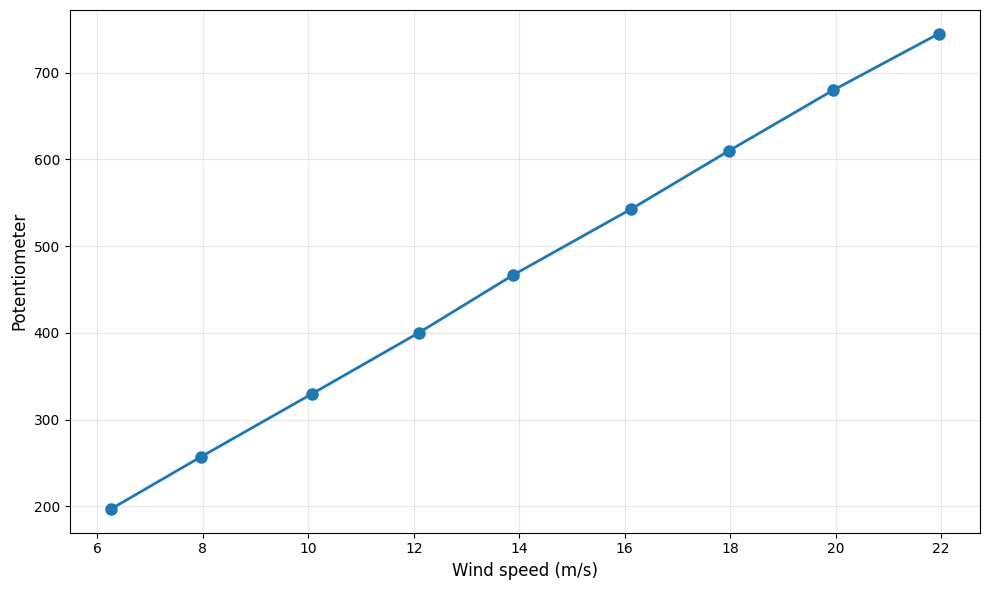

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Data from the image
windspeed = [6.257634463, 7.96009584, 10.0756608, 12.09018679,
             13.89173873, 16.12758994, 17.97709614, 19.95766285, 21.95565411]

potentiometer = [197, 257, 330, 400, 467, 543, 610, 680, 745]

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(windspeed, potentiometer, 'o-', linewidth=2, markersize=8)
plt.xlabel('Wind speed (m/s)', fontsize=12)
plt.ylabel('Potentiometer', fontsize=12)
plt.title('', fontsize=14)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the plot
#plt.savefig('/mnt/user-data/outputs/windspeed_plot.png', dpi=300, bbox_inches='tight')
#print("Plot saved successfully!")

# Show the plot
plt.show()

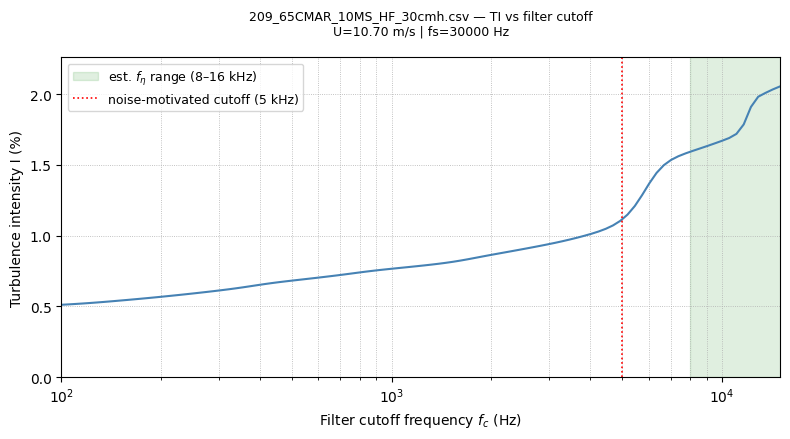

In [ ]:
# --- TI vs cutoff sweep for specific file ---
target_file = "209_65CMAR_10MS_HF_30cmh.csv"
target_path = None

for filepath in all_csv_files:
    if os.path.basename(filepath) == target_file:
        target_path = filepath
        break

if target_path is None:
    print(f"File {target_file} not found.")
else:
    df = pd.read_csv(target_path)
    u = df.iloc[:, -1].to_numpy(dtype=float)
    u = u[np.isfinite(u)]

    U = np.mean(u)
    u_fluc = u - U
    fs = fs_hf

    cutoffs = np.logspace(2, np.log10(fs / 2), 100)  # 100 Hz to Nyquist
    ti_vs_cutoff = []

    for fc in cutoffs:
        u_filt = lowpass_filter(u_fluc, fc, fs)
        sigma2_filt = np.mean(u_filt**2)
        ti_vs_cutoff.append(100 * np.sqrt(sigma2_filt) / U)

    fig, ax = plt.subplots(figsize=(8, 4.5))

    ax.semilogx(cutoffs, ti_vs_cutoff, color='steelblue', lw=1.5)

    # Kolmogorov frequency band
    ax.axvspan(8000, 16000, alpha=0.12, color='green',
               label=r'est. $f_\eta$ range (8–16 kHz)')
    # Noise-motivated manual cutoff
    ax.axvline(5000, color='red', linestyle=':', lw=1.2,
           label=r'noise-motivated cutoff (5 kHz)')

    ax.set_xlabel(r'Filter cutoff frequency $f_c$ (Hz)')
    ax.set_ylabel(r'Turbulence intensity I (%)')
    ax.grid(True, which='both', ls=':', lw=0.6)
    ax.legend(fontsize=9)
    ax.set_xlim([cutoffs[0], cutoffs[-1]])
    ax.set_ylim([0, max(ti_vs_cutoff) * 1.1])
    ax.set_title(
        f"{target_file} — TI vs filter cutoff\nU={U:.2f} m/s | fs={fs} Hz\n",
        fontsize=9
    )

    plt.tight_layout()
    plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


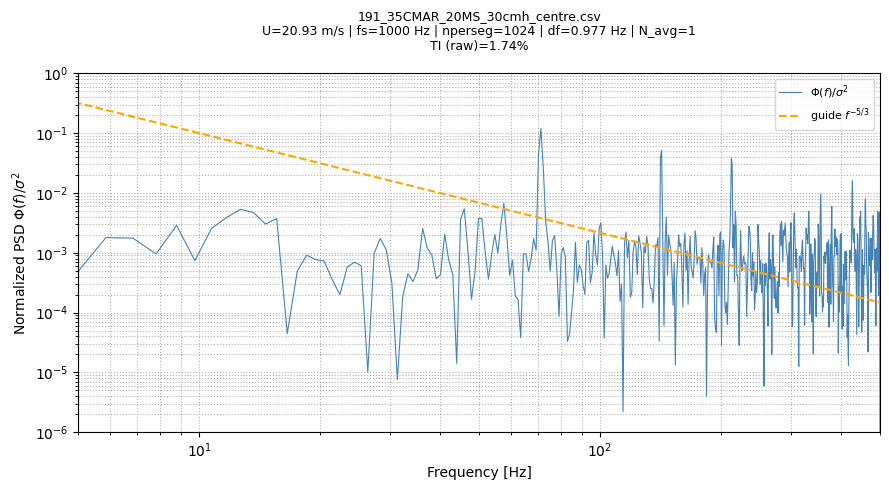

191_35CMAR_20MS_30cmh_centre.csv: fs=1000 Hz | nperseg=1024 | df=0.977 Hz | N_avg=1 | U=20.928 m/s | TI_raw=1.74% | TI_filtered=1.74%


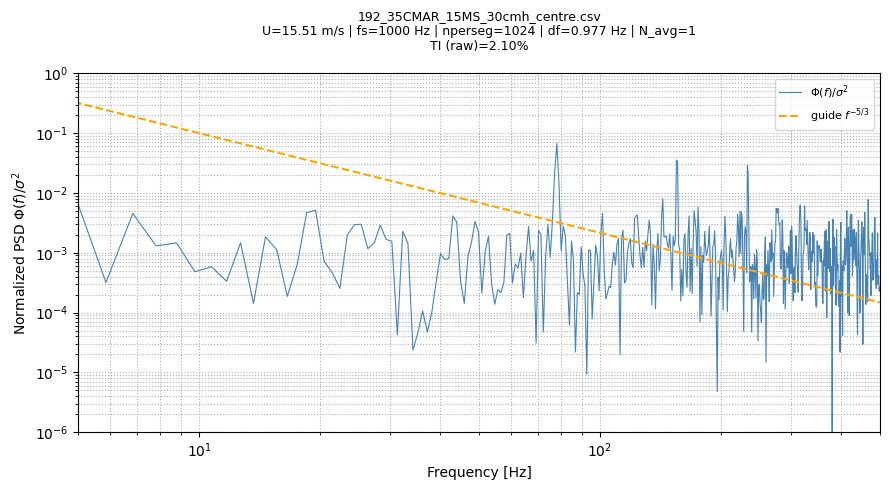

192_35CMAR_15MS_30cmh_centre.csv: fs=1000 Hz | nperseg=1024 | df=0.977 Hz | N_avg=1 | U=15.514 m/s | TI_raw=2.10% | TI_filtered=2.10%


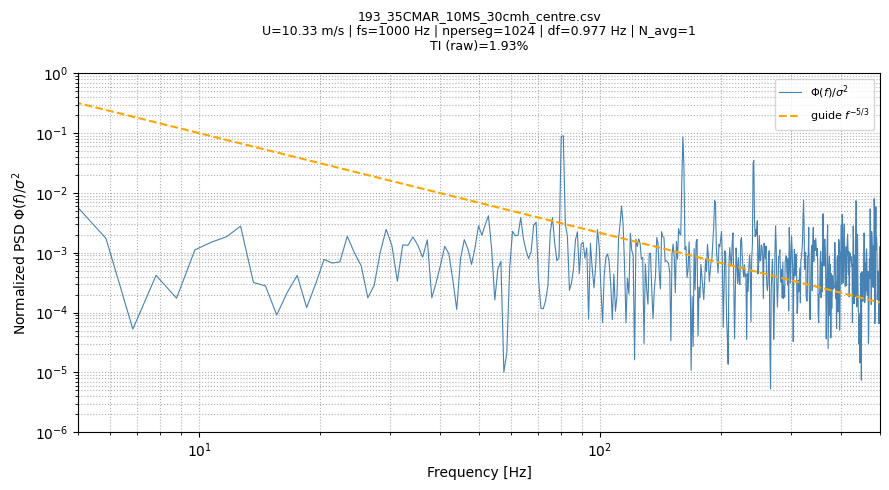

193_35CMAR_10MS_30cmh_centre.csv: fs=1000 Hz | nperseg=1024 | df=0.977 Hz | N_avg=1 | U=10.333 m/s | TI_raw=1.93% | TI_filtered=1.93%


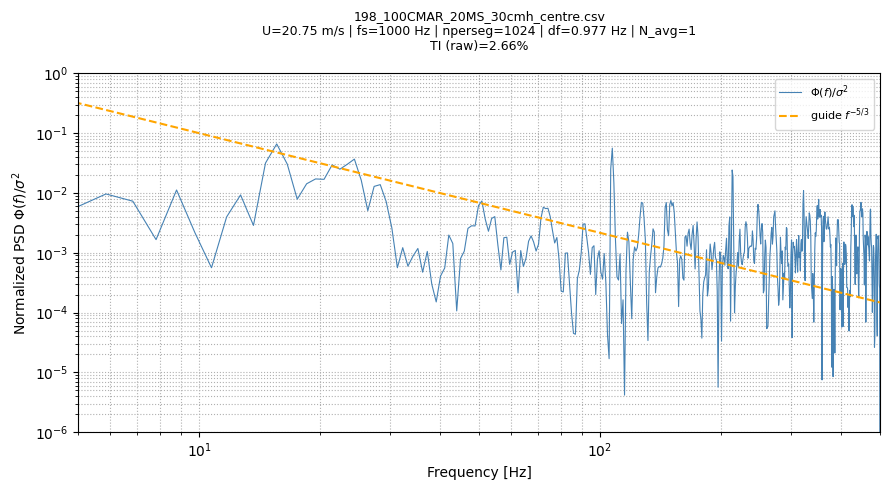

198_100CMAR_20MS_30cmh_centre.csv: fs=1000 Hz | nperseg=1024 | df=0.977 Hz | N_avg=1 | U=20.751 m/s | TI_raw=2.66% | TI_filtered=2.66%


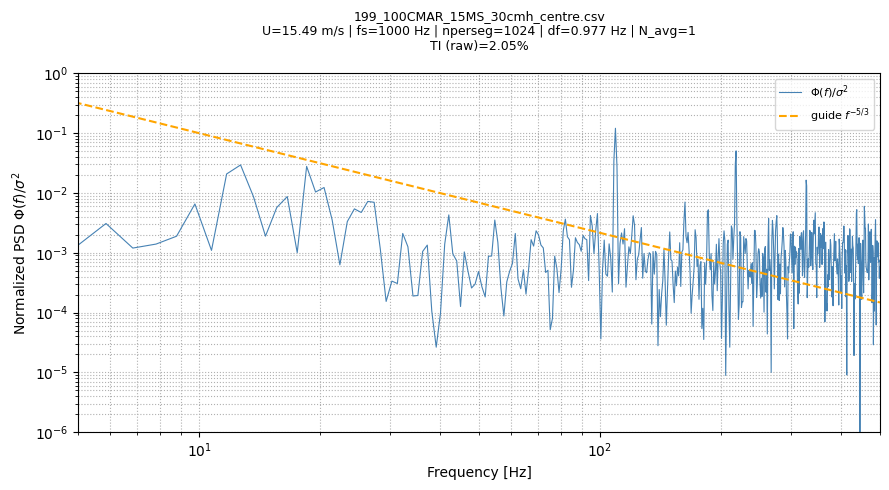

199_100CMAR_15MS_30cmh_centre.csv: fs=1000 Hz | nperseg=1024 | df=0.977 Hz | N_avg=1 | U=15.492 m/s | TI_raw=2.05% | TI_filtered=2.05%


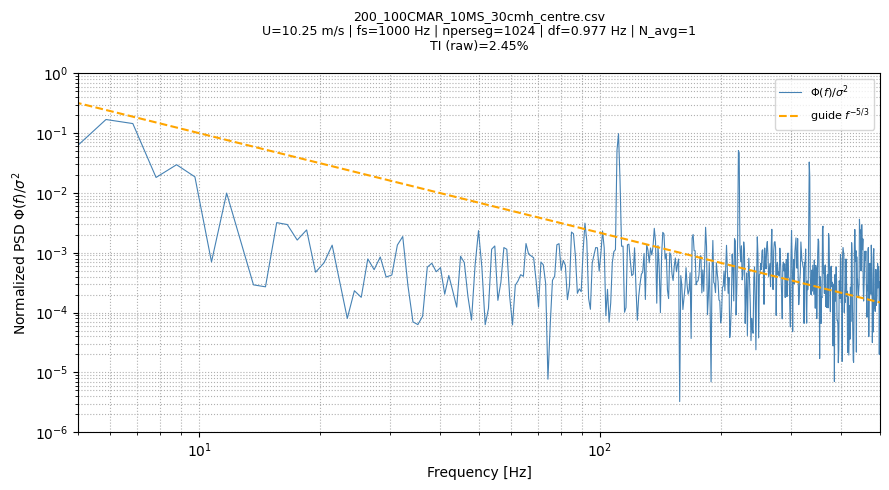

200_100CMAR_10MS_30cmh_centre.csv: fs=1000 Hz | nperseg=1024 | df=0.977 Hz | N_avg=1 | U=10.255 m/s | TI_raw=2.45% | TI_filtered=2.45%


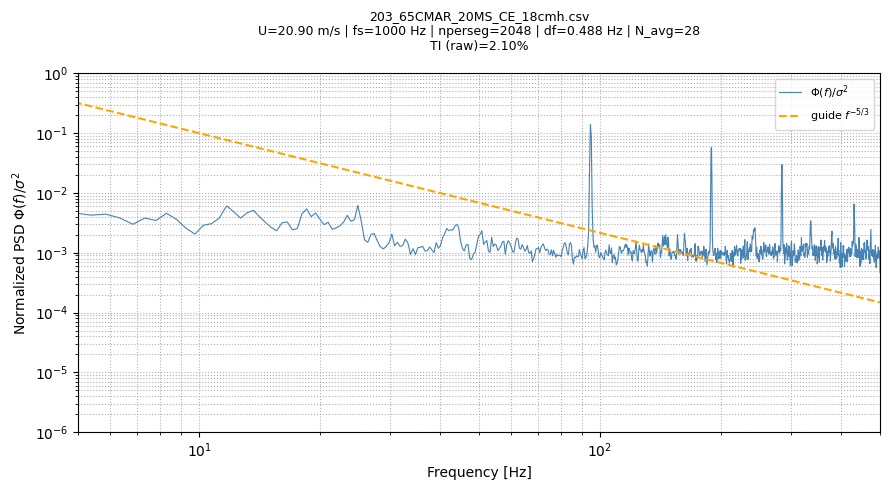

203_65CMAR_20MS_CE_18cmh.csv: fs=1000 Hz | nperseg=2048 | df=0.488 Hz | N_avg=28 | U=20.900 m/s | TI_raw=2.10% | TI_filtered=2.10%


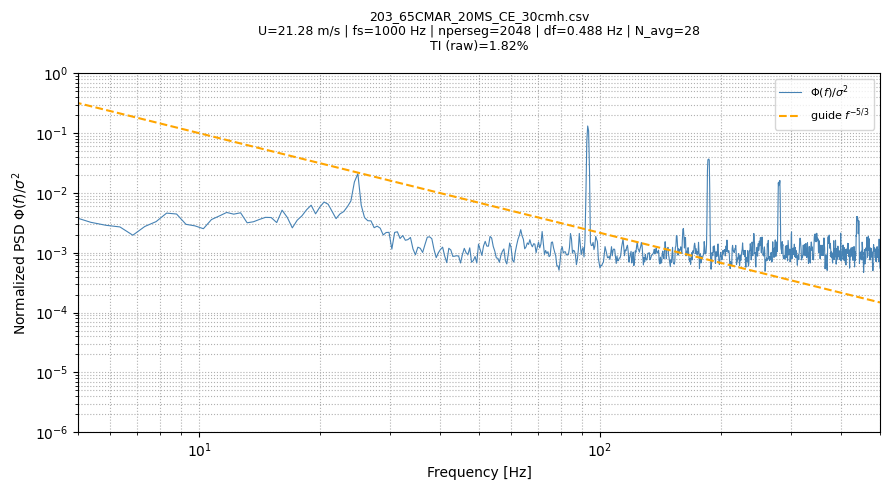

203_65CMAR_20MS_CE_30cmh.csv: fs=1000 Hz | nperseg=2048 | df=0.488 Hz | N_avg=28 | U=21.280 m/s | TI_raw=1.82% | TI_filtered=1.82%


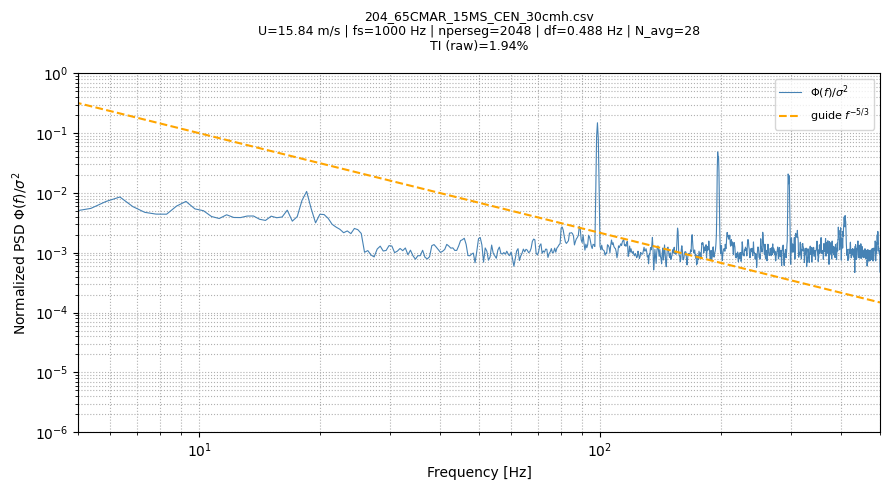

204_65CMAR_15MS_CEN_30cmh.csv: fs=1000 Hz | nperseg=2048 | df=0.488 Hz | N_avg=28 | U=15.837 m/s | TI_raw=1.94% | TI_filtered=1.94%


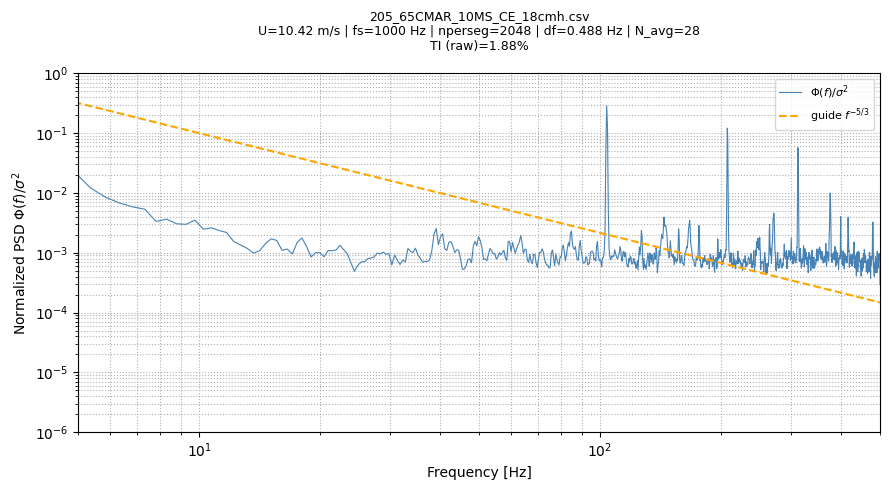

205_65CMAR_10MS_CE_18cmh.csv: fs=1000 Hz | nperseg=2048 | df=0.488 Hz | N_avg=28 | U=10.423 m/s | TI_raw=1.88% | TI_filtered=1.88%


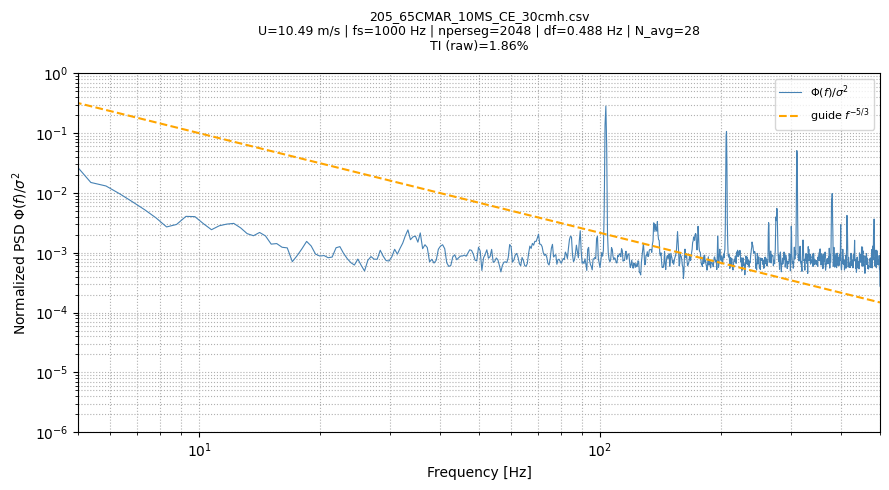

205_65CMAR_10MS_CE_30cmh.csv: fs=1000 Hz | nperseg=2048 | df=0.488 Hz | N_avg=28 | U=10.490 m/s | TI_raw=1.86% | TI_filtered=1.86%


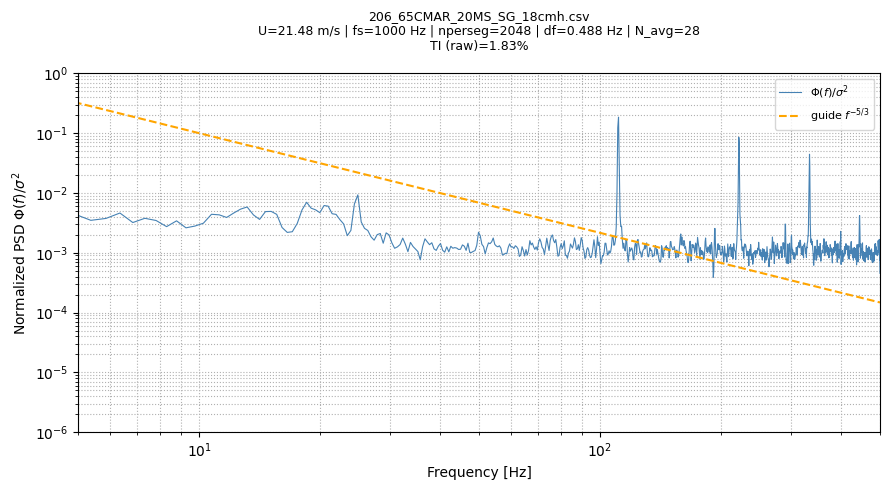

206_65CMAR_20MS_SG_18cmh.csv: fs=1000 Hz | nperseg=2048 | df=0.488 Hz | N_avg=28 | U=21.477 m/s | TI_raw=1.83% | TI_filtered=1.83%


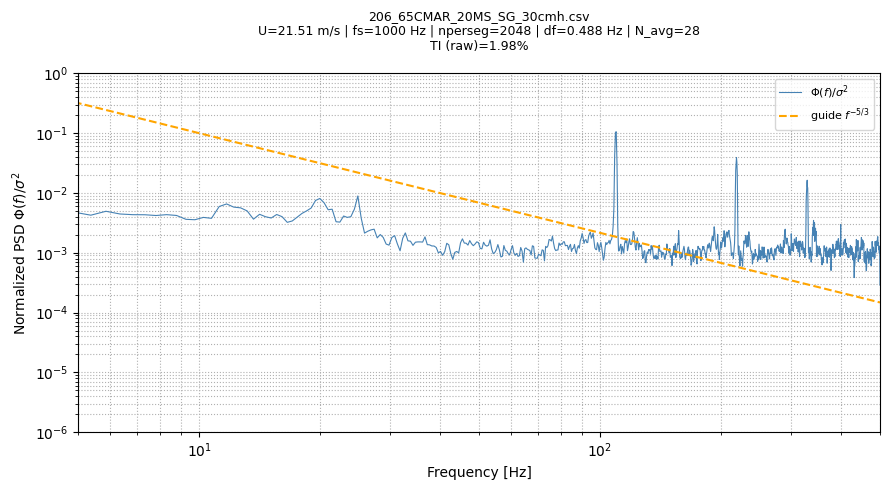

206_65CMAR_20MS_SG_30cmh.csv: fs=1000 Hz | nperseg=2048 | df=0.488 Hz | N_avg=28 | U=21.510 m/s | TI_raw=1.98% | TI_filtered=1.98%


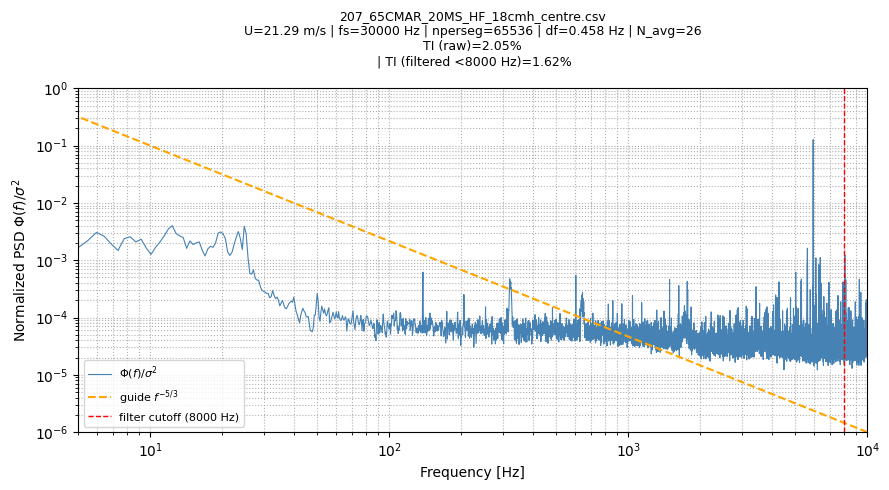

207_65CMAR_20MS_HF_18cmh_centre.csv: fs=30000 Hz | nperseg=65536 | df=0.458 Hz | N_avg=26 | U=21.287 m/s | TI_raw=2.05% | TI_filtered=1.62%


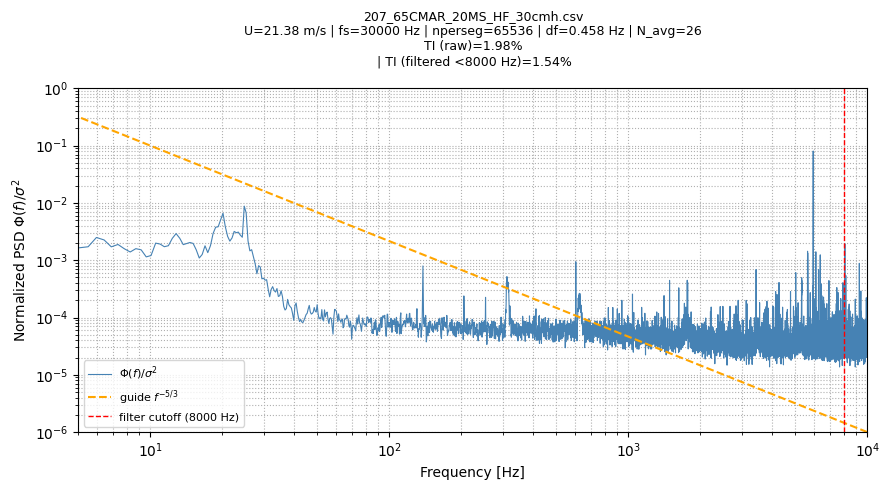

207_65CMAR_20MS_HF_30cmh.csv: fs=30000 Hz | nperseg=65536 | df=0.458 Hz | N_avg=26 | U=21.384 m/s | TI_raw=1.98% | TI_filtered=1.54%


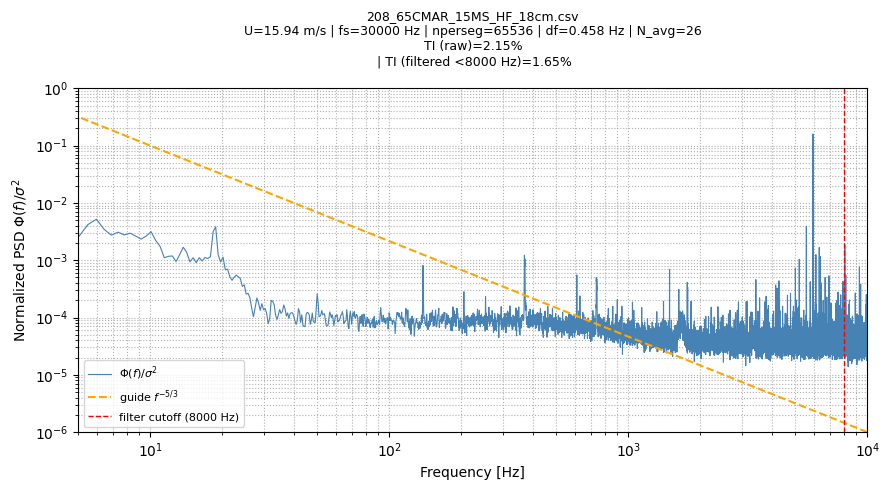

208_65CMAR_15MS_HF_18cm.csv: fs=30000 Hz | nperseg=65536 | df=0.458 Hz | N_avg=26 | U=15.943 m/s | TI_raw=2.15% | TI_filtered=1.65%


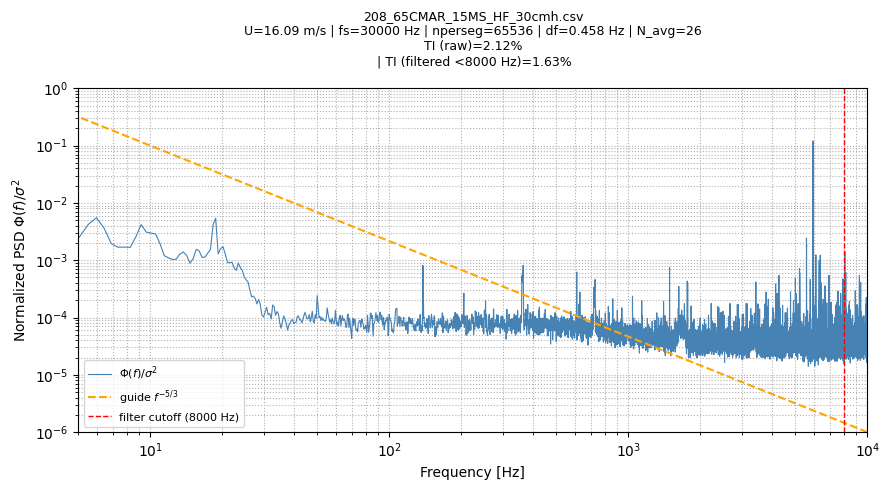

208_65CMAR_15MS_HF_30cmh.csv: fs=30000 Hz | nperseg=65536 | df=0.458 Hz | N_avg=26 | U=16.086 m/s | TI_raw=2.12% | TI_filtered=1.63%


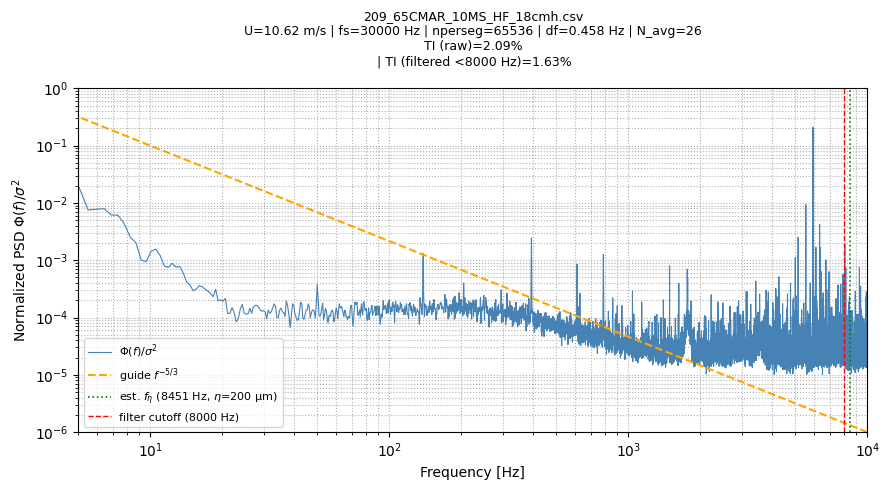

209_65CMAR_10MS_HF_18cmh.csv: fs=30000 Hz | nperseg=65536 | df=0.458 Hz | N_avg=26 | U=10.620 m/s | TI_raw=2.09% | TI_filtered=1.63%


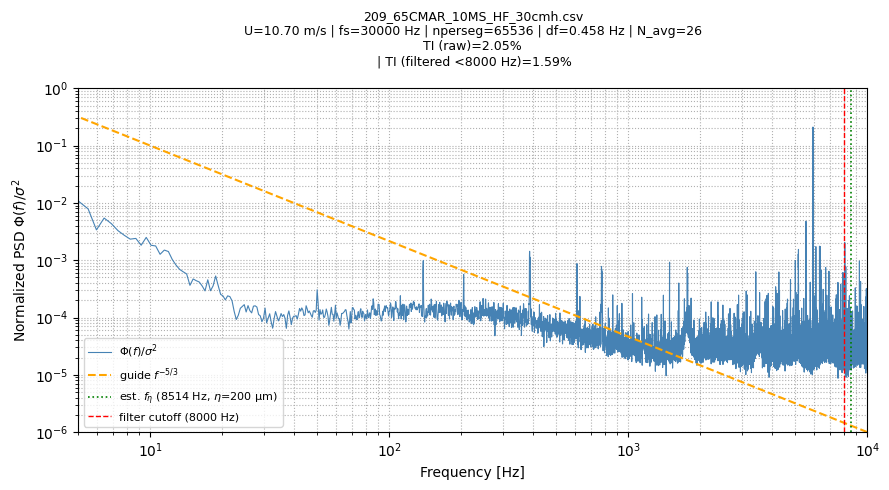

209_65CMAR_10MS_HF_30cmh.csv: fs=30000 Hz | nperseg=65536 | df=0.458 Hz | N_avg=26 | U=10.699 m/s | TI_raw=2.05% | TI_filtered=1.59%


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch, butter, sosfilt

# -------- SETTINGS ----------
folder_path = "/content/drive/MyDrive/THESIS IAT/TIMO CSV flute pan data/long"

# Sampling rates by folder
fs_normal = 1000      # Hz for files in /long
fs_hf = 30000         # Hz for files in /long/hf

# Welch settings by folder
nperseg_normal = 2048
nperseg_hf = 65536
overlap_frac = 0.5
window = "hann"

# Low-pass filter cutoff for physical variance estimation (hf only)
# Set to estimated Kolmogorov frequency — adjust once you compute f_eta properly
cutoff_hz = 8000      # Hz

# Plot x-limits by folder
default_fmax_plot = 1000
high_fmax_plot = 10000
# ---------------------------


def lowpass_filter(signal, cutoff, fs, order=6):
    """Butterworth low-pass filter applied as forward-backward SOS for zero phase shift."""
    nyq = fs / 2
    if cutoff >= nyq:
        return signal  # no filtering needed if cutoff is at or above Nyquist
    sos = butter(order, cutoff, fs=fs, btype='low', output='sos')
    return sosfilt(sos, signal)


# Find all CSV files recursively
all_csv_files = sorted(glob.glob(os.path.join(folder_path, "**", "*.csv"), recursive=True))

for filepath in all_csv_files:
    file = os.path.basename(filepath)

    # Detect hf files by folder
    is_hf = f"{os.sep}hf{os.sep}" in filepath

    # Apply settings by folder
    fs = fs_hf if is_hf else fs_normal
    nperseg_target = nperseg_hf if is_hf else nperseg_normal
    xmax_plot = high_fmax_plot if is_hf else default_fmax_plot

    try:
        df = pd.read_csv(filepath)
    except Exception as e:
        print(f"Skipping {filepath}: {e}")
        continue

    # Last column = calibrated velocity u [m/s]
    u = df.iloc[:, -1].to_numpy(dtype=float)
    u = u[np.isfinite(u)]

    if len(u) < 1000:
        print(f"Skipping {file}: too short.")
        continue

    # Mean speed and fluctuations
    U = np.mean(u)
    u_fluc = u - U

    # --- RAW variance (full bandwidth, includes noise) ---
    sigma2_raw = np.mean(u_fluc**2)

    if sigma2_raw <= 0:
        print(f"Skipping {file}: zero or invalid variance.")
        continue

    # --- FILTERED variance (physically meaningful, hf files only) ---
    if is_hf:
        u_filtered = lowpass_filter(u_fluc, cutoff_hz, fs)
        sigma2_filtered = np.mean(u_filtered**2)
        sigma2 = sigma2_raw  # keep raw for PSD normalization so shape is unchanged
    else:
        sigma2_filtered = sigma2_raw
        sigma2 = sigma2_raw

    # Welch PSD in frequency
    nperseg = min(nperseg_target, len(u_fluc))
    if nperseg < 256:
        print(f"Skipping {file}: nperseg too small.")
        continue

    noverlap = int(nperseg * overlap_frac)

    f, Phi_f = welch(
        u_fluc,
        fs=fs,
        window=window,
        nperseg=nperseg,
        noverlap=noverlap,
        detrend=False,
        scaling="density"
    )

    # Remove f=0
    f = f[1:]
    Phi_f = Phi_f[1:]

    if len(f) == 0:
        print(f"Skipping {file}: no frequency data after removing f=0.")
        continue

    # Normalize PSD by raw variance so spectral shape is preserved
    Phi_norm = Phi_f / sigma2_raw

    # Build -5/3 guide line
    fmin_guide = 10.0
    guide_intercept = 1e-1
    guide = guide_intercept * (f / fmin_guide) ** (-5/3)

    # Never exceed Nyquist
    xmax_plot = min(xmax_plot, fs / 2)

    # Frequency resolution
    dfreq = fs / nperseg

    # Estimated Kolmogorov frequency (eta ~ 200 microns assumed — adjust as needed)
    eta_estimate = 200e-6   # metres
    f_eta = U / (2 * np.pi * eta_estimate)

    # Number of Welch averages
    n_averages = int((len(u_fluc) - noverlap) / (nperseg - noverlap))

    # Turbulence intensities
    ti_raw      = 100 * np.sqrt(sigma2_raw) / U if U != 0 else np.nan
    ti_filtered = 100 * np.sqrt(sigma2_filtered) / U if U != 0 else np.nan

    # --- Plot ---
    fig, ax = plt.subplots(figsize=(9, 5))

    ax.loglog(f, Phi_norm, color='steelblue', lw=0.8, label=r"$\Phi(f)/\sigma^2$")
    ax.loglog(f, guide, '--', color='orange', label=r"guide $f^{-5/3}$")

    # Kolmogorov frequency marker
    if f_eta < xmax_plot:
        ax.axvline(f_eta, color='green', linestyle=':', lw=1.2,
                   label=rf"est. $f_\eta$ ({f_eta:.0f} Hz, $\eta$=200 µm)")

    # Cutoff marker for hf files
    if is_hf:
        ax.axvline(cutoff_hz, color='red', linestyle='--', lw=1.0,
                   label=rf"filter cutoff ({cutoff_hz} Hz)")

    ax.grid(True, which="both", ls=":")
    ax.set_xlabel("Frequency [Hz]")
    ax.set_ylabel(r"Normalized PSD $\Phi(f)/\sigma^2$")
    ax.set_xlim([5, xmax_plot])
    ax.set_ylim([1e-6, 1])

    title = (
        f"{file}\n"
        f"U={U:.2f} m/s | fs={fs} Hz | nperseg={nperseg} | "
        f"df={dfreq:.3f} Hz | N_avg={n_averages}\n"
        f"TI (raw)={ti_raw:.2f}%\n"
    )
    if is_hf:
        title += f" | TI (filtered <{cutoff_hz} Hz)={ti_filtered:.2f}%\n"

    ax.set_title(title, fontsize=9)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

    print(
        f"{file}: fs={fs} Hz | nperseg={nperseg} | df={dfreq:.3f} Hz | "
        f"N_avg={n_averages} | U={U:.3f} m/s | "
        f"TI_raw={ti_raw:.2f}% | TI_filtered={ti_filtered:.2f}%"
    )

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


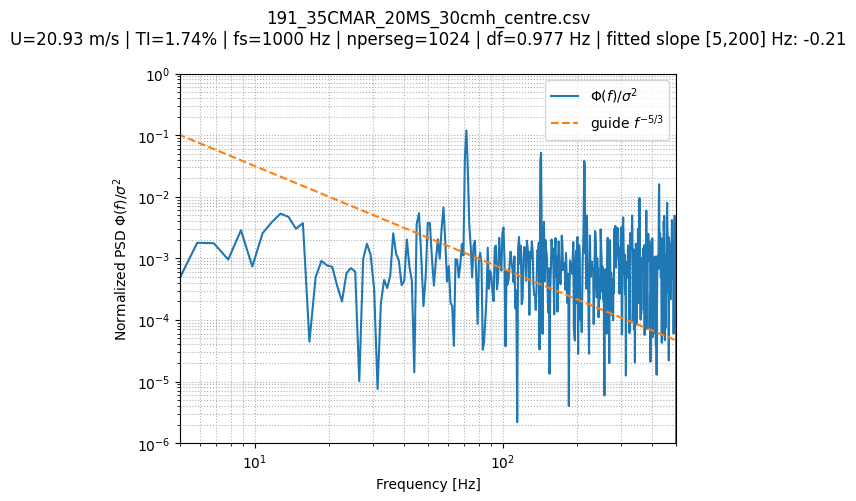

191_35CMAR_20MS_30cmh_centre.csv: fs=1000 Hz | nperseg=1024 | df=0.977 Hz | U=20.928 m/s | TI=1.74% | slope=-0.20700821520751925


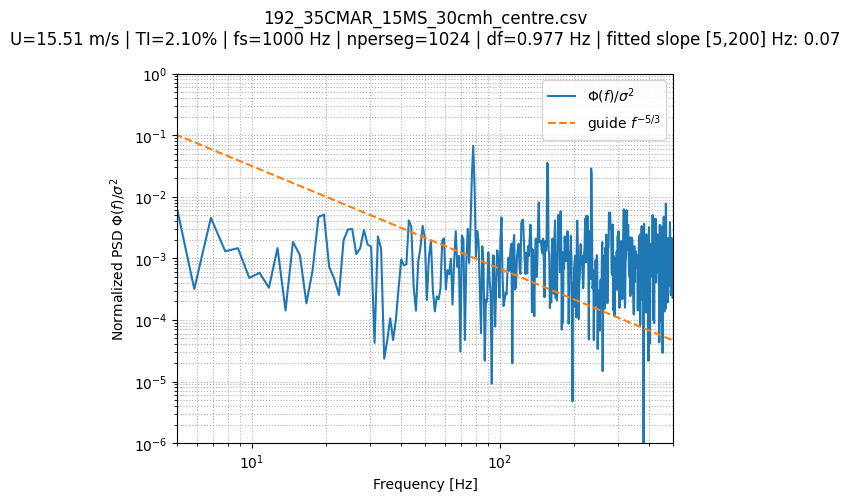

192_35CMAR_15MS_30cmh_centre.csv: fs=1000 Hz | nperseg=1024 | df=0.977 Hz | U=15.514 m/s | TI=2.10% | slope=0.06792365230090136


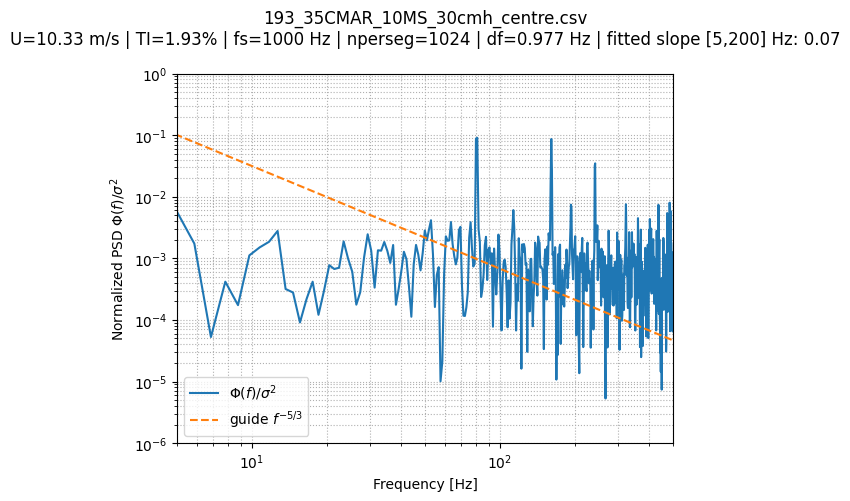

193_35CMAR_10MS_30cmh_centre.csv: fs=1000 Hz | nperseg=1024 | df=0.977 Hz | U=10.333 m/s | TI=1.93% | slope=0.07366320544268719


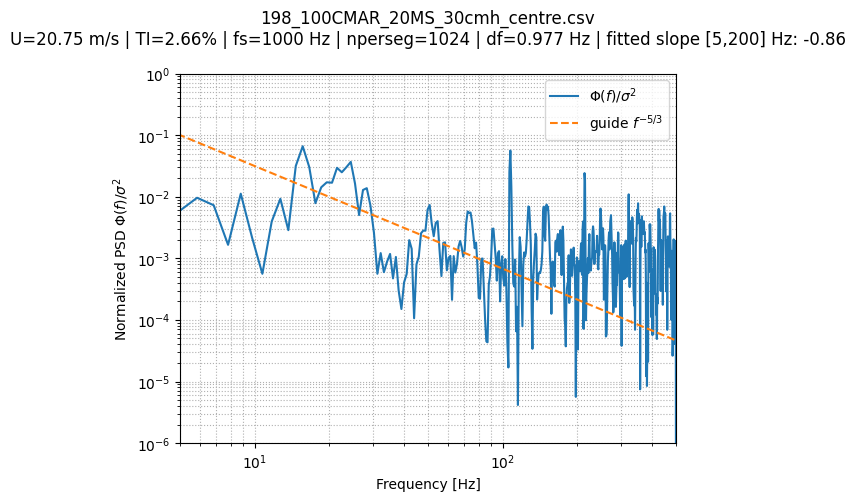

198_100CMAR_20MS_30cmh_centre.csv: fs=1000 Hz | nperseg=1024 | df=0.977 Hz | U=20.751 m/s | TI=2.66% | slope=-0.8573660107587747


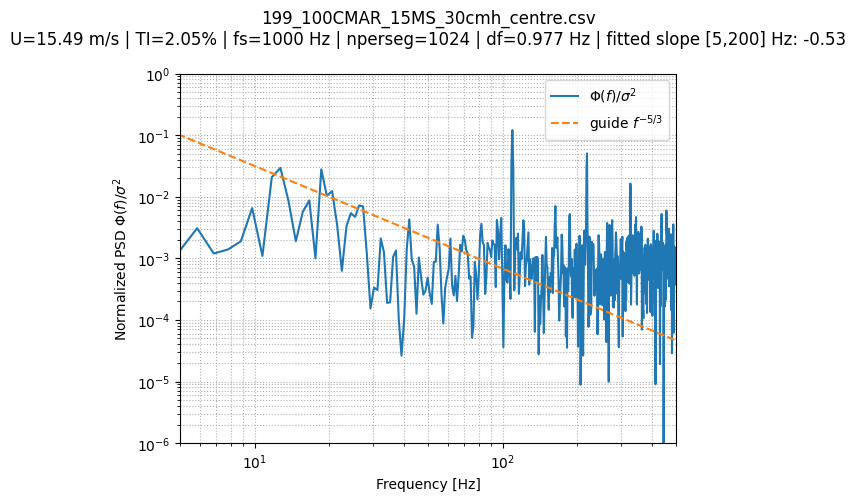

199_100CMAR_15MS_30cmh_centre.csv: fs=1000 Hz | nperseg=1024 | df=0.977 Hz | U=15.492 m/s | TI=2.05% | slope=-0.5251618193238281


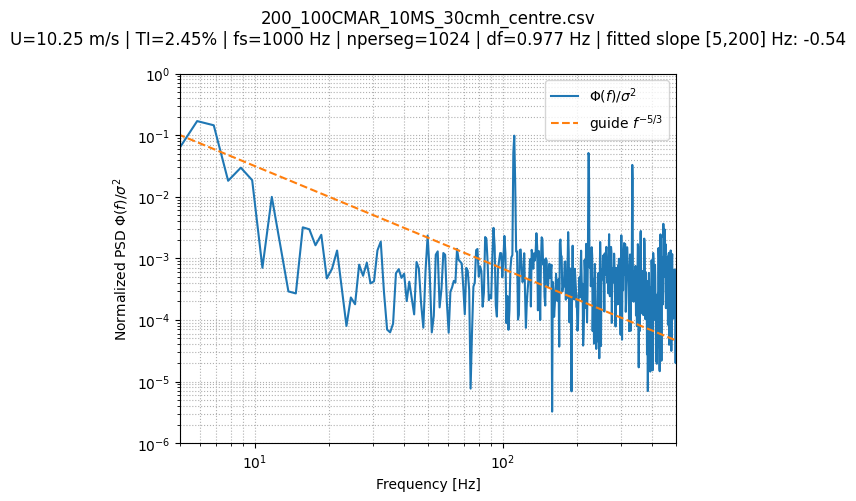

200_100CMAR_10MS_30cmh_centre.csv: fs=1000 Hz | nperseg=1024 | df=0.977 Hz | U=10.255 m/s | TI=2.45% | slope=-0.5409102913860554


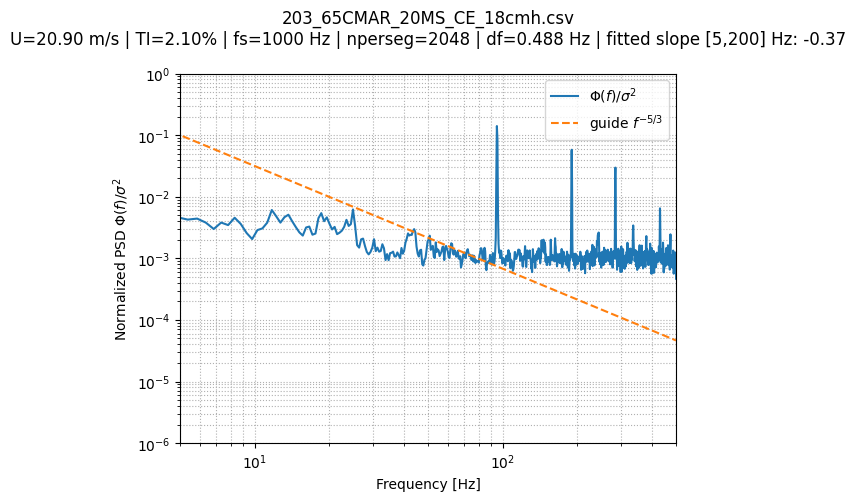

203_65CMAR_20MS_CE_18cmh.csv: fs=1000 Hz | nperseg=2048 | df=0.488 Hz | U=20.900 m/s | TI=2.10% | slope=-0.36663423767778236


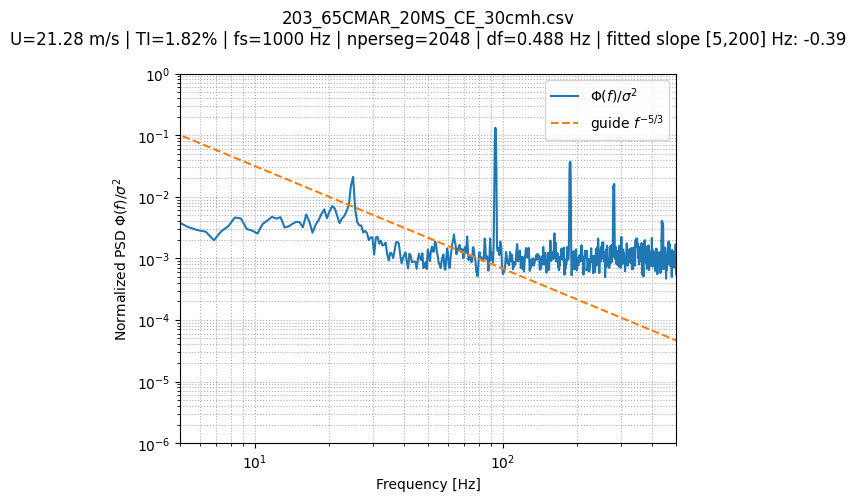

203_65CMAR_20MS_CE_30cmh.csv: fs=1000 Hz | nperseg=2048 | df=0.488 Hz | U=21.280 m/s | TI=1.82% | slope=-0.3917066346349421


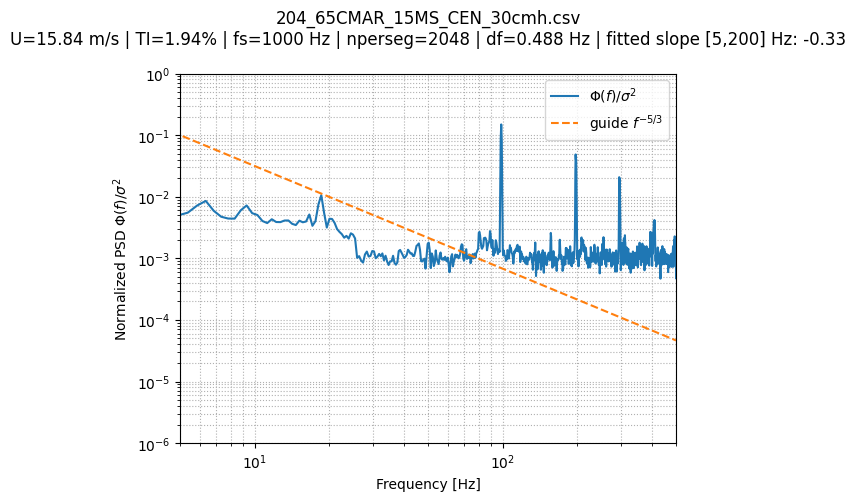

204_65CMAR_15MS_CEN_30cmh.csv: fs=1000 Hz | nperseg=2048 | df=0.488 Hz | U=15.837 m/s | TI=1.94% | slope=-0.3252227511728376


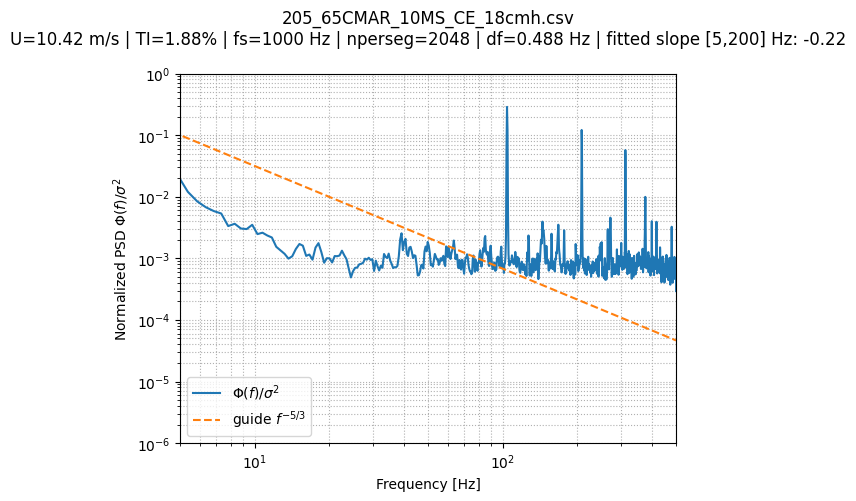

205_65CMAR_10MS_CE_18cmh.csv: fs=1000 Hz | nperseg=2048 | df=0.488 Hz | U=10.423 m/s | TI=1.88% | slope=-0.22094042032859415


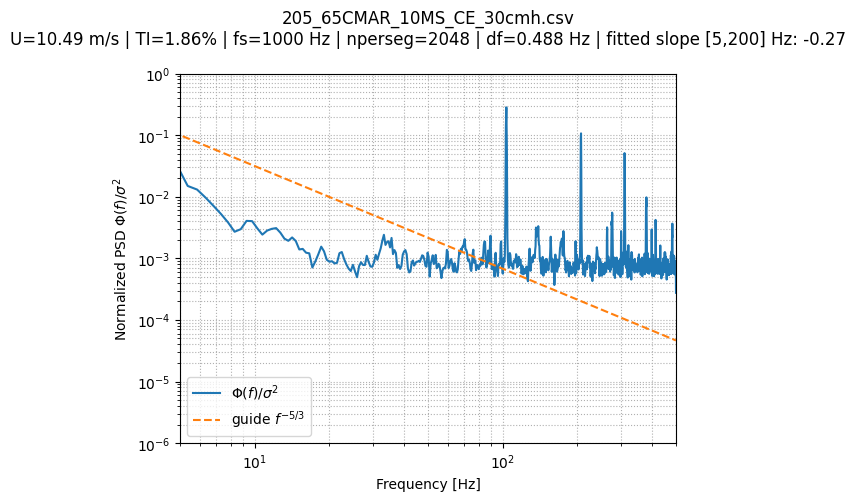

205_65CMAR_10MS_CE_30cmh.csv: fs=1000 Hz | nperseg=2048 | df=0.488 Hz | U=10.490 m/s | TI=1.86% | slope=-0.2675021256783485


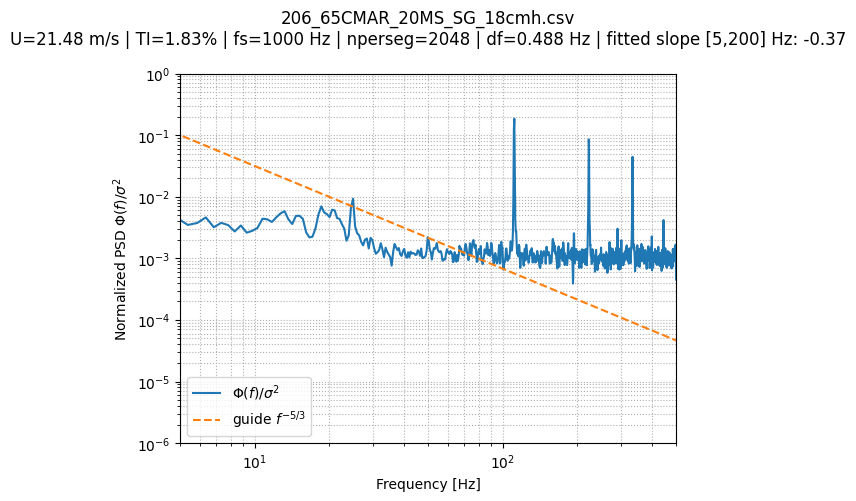

206_65CMAR_20MS_SG_18cmh.csv: fs=1000 Hz | nperseg=2048 | df=0.488 Hz | U=21.477 m/s | TI=1.83% | slope=-0.37446167022586346


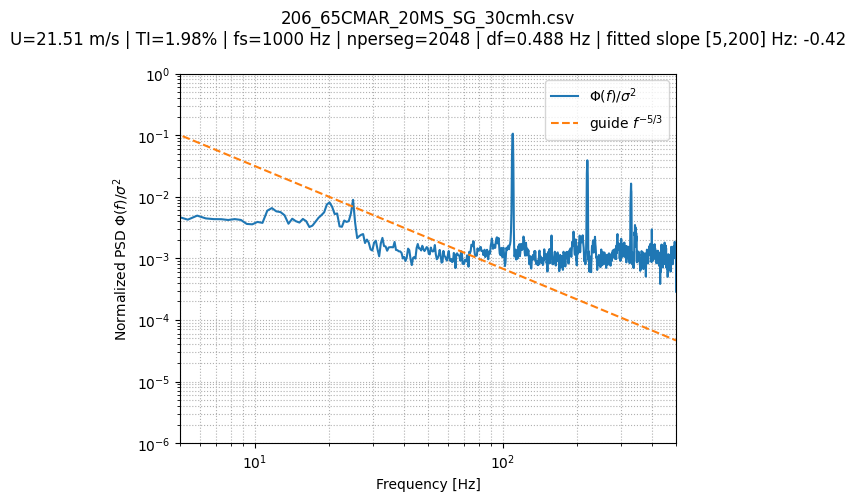

206_65CMAR_20MS_SG_30cmh.csv: fs=1000 Hz | nperseg=2048 | df=0.488 Hz | U=21.510 m/s | TI=1.98% | slope=-0.4206240703686295


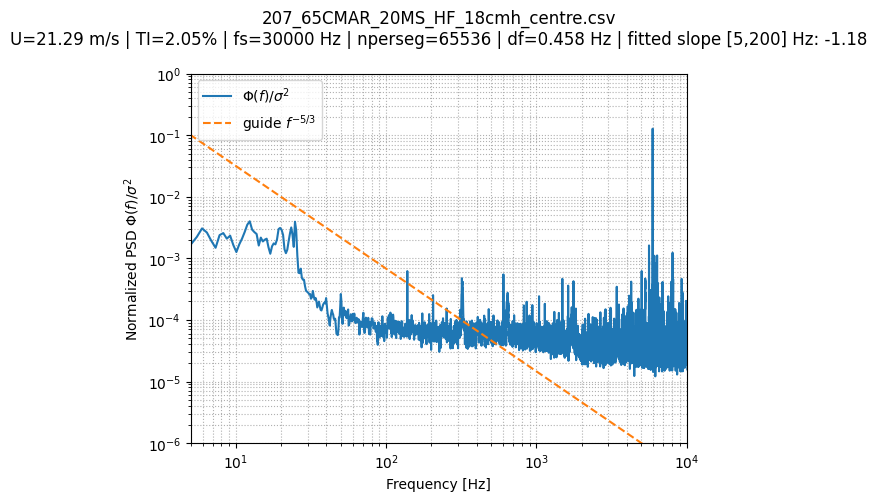

207_65CMAR_20MS_HF_18cmh_centre.csv: fs=30000 Hz | nperseg=65536 | df=0.458 Hz | U=21.287 m/s | TI=2.05% | slope=-1.1792621625234527


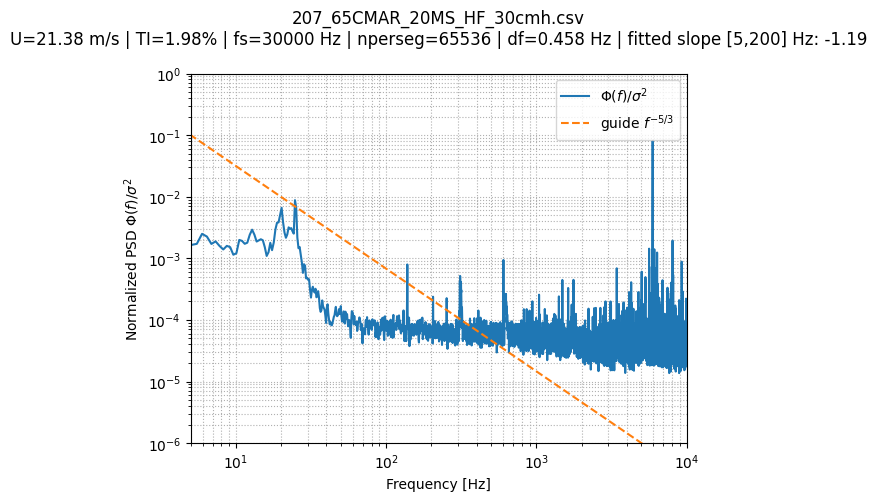

207_65CMAR_20MS_HF_30cmh.csv: fs=30000 Hz | nperseg=65536 | df=0.458 Hz | U=21.384 m/s | TI=1.98% | slope=-1.1857036321050227


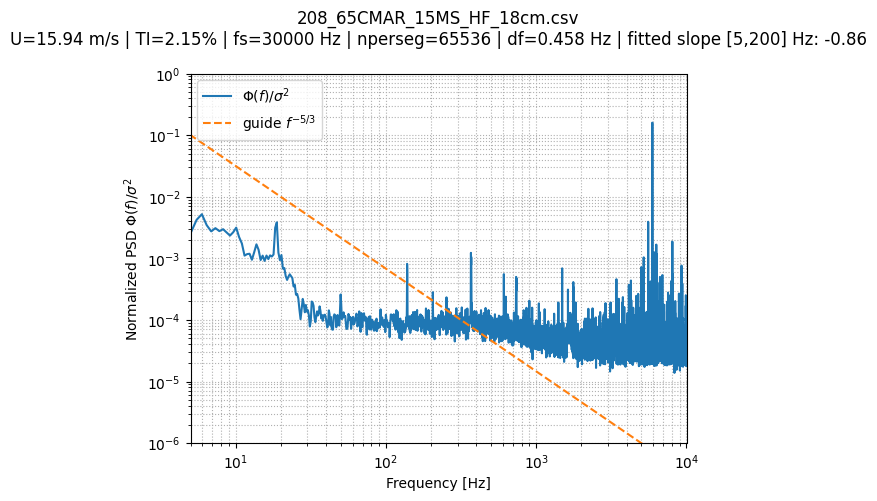

208_65CMAR_15MS_HF_18cm.csv: fs=30000 Hz | nperseg=65536 | df=0.458 Hz | U=15.943 m/s | TI=2.15% | slope=-0.858593628332808


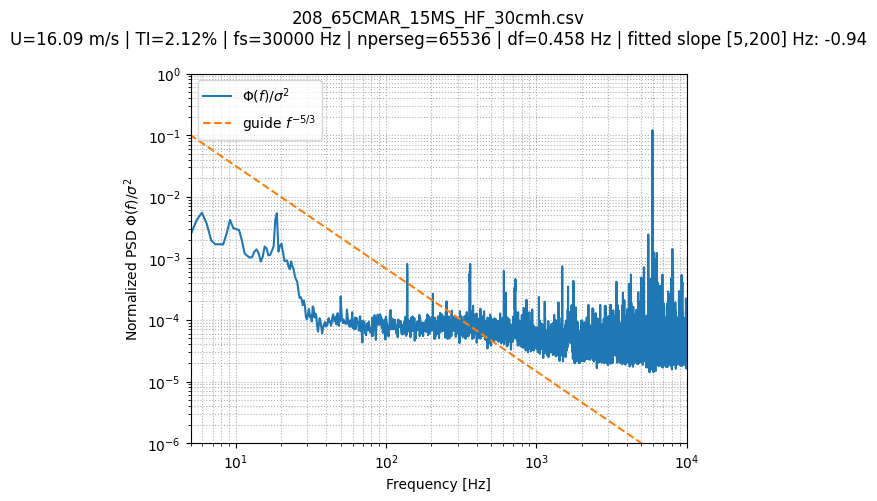

208_65CMAR_15MS_HF_30cmh.csv: fs=30000 Hz | nperseg=65536 | df=0.458 Hz | U=16.086 m/s | TI=2.12% | slope=-0.9396133772529158


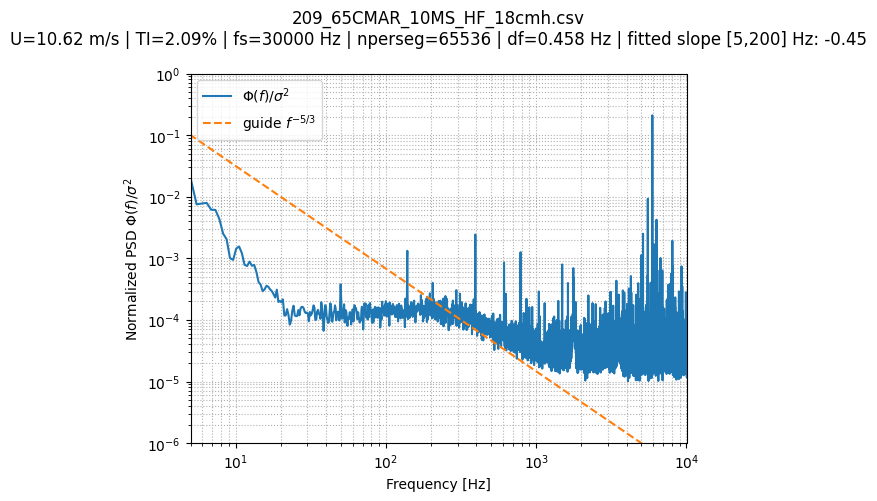

209_65CMAR_10MS_HF_18cmh.csv: fs=30000 Hz | nperseg=65536 | df=0.458 Hz | U=10.620 m/s | TI=2.09% | slope=-0.4526289065661894


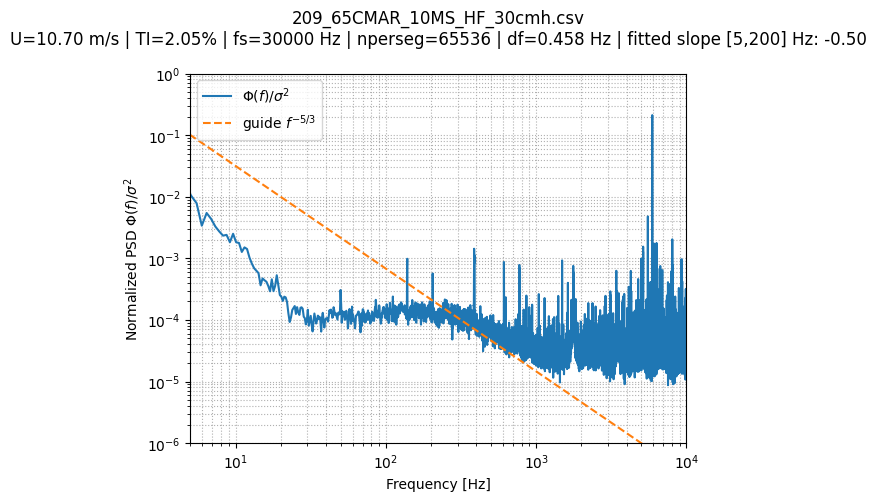

209_65CMAR_10MS_HF_30cmh.csv: fs=30000 Hz | nperseg=65536 | df=0.458 Hz | U=10.699 m/s | TI=2.05% | slope=-0.496165828950301


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

# -------- SETTINGS ----------
folder_path = "/content/drive/MyDrive/THESIS IAT/TIMO CSV flute pan data/long"

# Sampling rates by folder
fs_normal = 1000      # Hz for files in /long
fs_hf = 30000         # Hz for files in /long/hf

# Welch settings by folder
nperseg_normal = 2048
nperseg_hf = 65536
overlap_frac = 0.5
window = "hann"

# Frequency range to fit slope
fmin_fit = 5.0        # Hz
fmax_fit = 200.0      # Hz

# Plot x-limits by folder
default_fmax_plot = 1000
high_fmax_plot = 10000
# ---------------------------

def fit_log_slope(x, y, xmin, xmax):
    m = (x >= xmin) & (x <= xmax) & np.isfinite(y) & (y > 0)
    if np.count_nonzero(m) < 10:
        return None, None, m
    slope, intercept = np.polyfit(np.log10(x[m]), np.log10(y[m]), 1)
    return slope, intercept, m

# Find all CSV files recursively
all_csv_files = sorted(glob.glob(os.path.join(folder_path, "**", "*.csv"), recursive=True))

for filepath in all_csv_files:
    file = os.path.basename(filepath)

    # Detect hf files by folder
    is_hf = f"{os.sep}hf{os.sep}" in filepath

    # Apply settings by folder
    fs = fs_hf if is_hf else fs_normal
    nperseg_target = nperseg_hf if is_hf else nperseg_normal
    xmax_plot = high_fmax_plot if is_hf else default_fmax_plot

    try:
        df = pd.read_csv(filepath)
    except Exception as e:
        print(f"Skipping {filepath}: {e}")
        continue

    # Last column = calibrated velocity u [m/s]
    u = df.iloc[:, -1].to_numpy(dtype=float)
    u = u[np.isfinite(u)]

    if len(u) < 1000:
        print(f"Skipping {file}: too short.")
        continue

    # Mean speed and fluctuations
    U = np.mean(u)
    u_fluc = u - U
    sigma2 = np.mean(u_fluc**2)

    if sigma2 <= 0:
        print(f"Skipping {file}: zero or invalid variance.")
        continue

    # Welch PSD in frequency
    nperseg = min(nperseg_target, len(u_fluc))
    if nperseg < 256:
        print(f"Skipping {file}: nperseg too small.")
        continue

    noverlap = int(nperseg * overlap_frac)

    f, Phi_f = welch(
        u_fluc,
        fs=fs,
        window=window,
        nperseg=nperseg,
        noverlap=noverlap,
        detrend=False,
        scaling="density"
    )

    # Remove f=0
    f = f[1:]
    Phi_f = Phi_f[1:]

    if len(f) == 0:
        print(f"Skipping {file}: no frequency data after removing f=0.")
        continue

    # Normalize PSD by variance
    Phi_norm = Phi_f / sigma2

    # Fit slope on chosen frequency band
    slope, intercept, mfit = fit_log_slope(f, Phi_norm, fmin_fit, fmax_fit)

    # Build -5/3 guide line with fixed intercept at 10^-1
    guide_intercept = 1e-1
    guide = guide_intercept * (f / fmin_fit) ** (-5/3)

    # Never exceed Nyquist
    xmax_plot = min(xmax_plot, fs / 2)

    # Frequency resolution
    dfreq = fs / nperseg

    # Plot
    plt.loglog(f, Phi_norm, label=r"$\Phi(f)/\sigma^2$")
    plt.loglog(f, guide, "--", label=r"guide $f^{-5/3}$")
    plt.grid(True, which="both", ls=":")
    plt.xlabel("Frequency [Hz]")
    plt.ylabel(r"Normalized PSD $\Phi(f)/\sigma^2$")
    plt.xlim([fmin_fit, xmax_plot])
    plt.ylim(1e-6,1)   # prevents y-axis from going below 0.5×10^-5

    ti_percent = 100 * np.sqrt(sigma2) / U if U != 0 else np.nan
    title = (
        f"{file}\n"
        f"U={U:.2f} m/s | TI={ti_percent:.2f}% | fs={fs} Hz | "
        f"nperseg={nperseg} | df={dfreq:.3f} Hz"
    )
    if slope is not None:
        title += f" | fitted slope [{fmin_fit:g},{fmax_fit:g}] Hz: {slope:.2f}\n"

    plt.title(title)
    plt.legend()
    plt.show()

    print(
        f"{file}: fs={fs} Hz | nperseg={nperseg} | df={dfreq:.3f} Hz | "
        f"U={U:.3f} m/s | TI={ti_percent:.2f}% | "
        f"slope={slope if slope is not None else 'N/A'}"
    )

Mounted at /content/drive


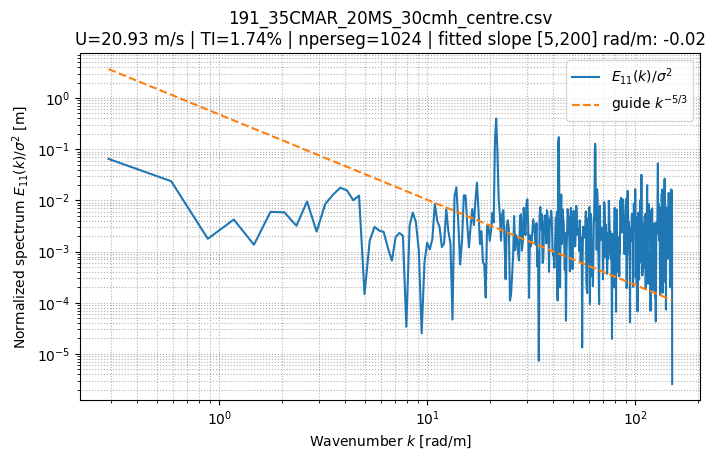

191_35CMAR_20MS_30cmh_centre.csv: U=20.928 m/s | TI=1.74% | slope=-0.01899076719577957


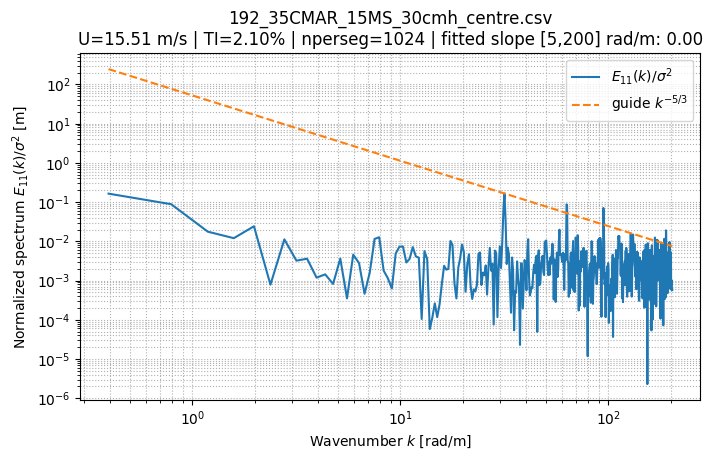

192_35CMAR_15MS_30cmh_centre.csv: U=15.514 m/s | TI=2.10% | slope=0.002110793666079692


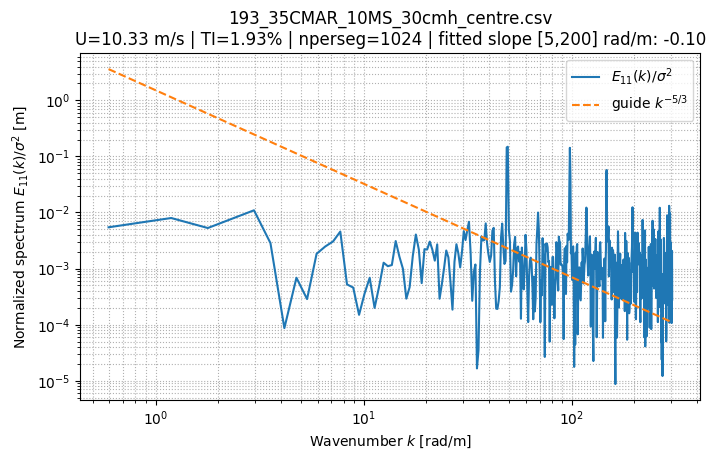

193_35CMAR_10MS_30cmh_centre.csv: U=10.333 m/s | TI=1.93% | slope=-0.10204644673941414


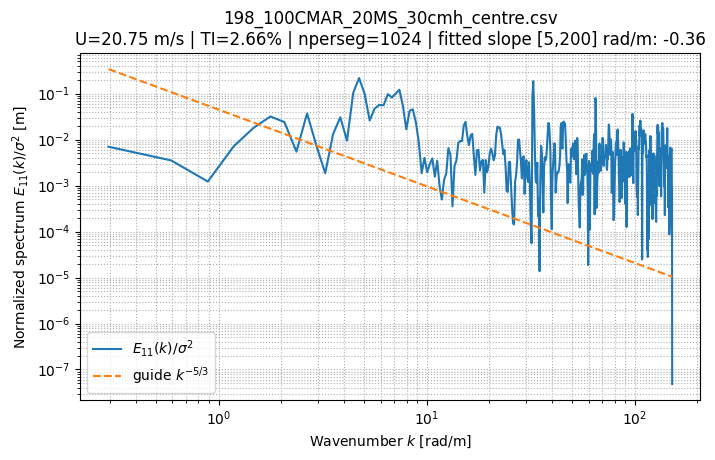

198_100CMAR_20MS_30cmh_centre.csv: U=20.751 m/s | TI=2.66% | slope=-0.3613970122267062


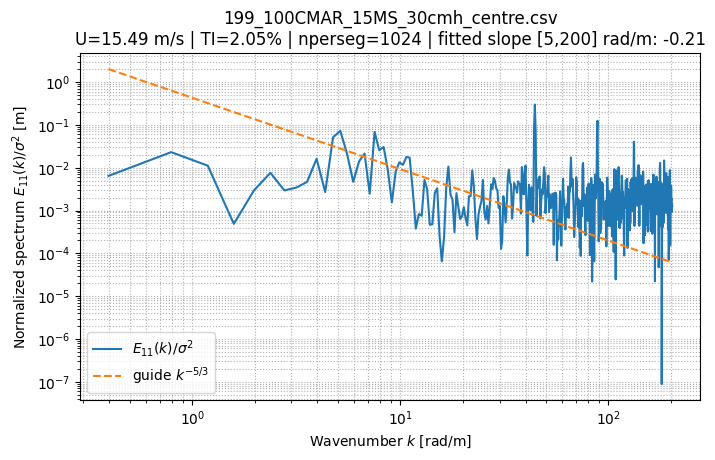

199_100CMAR_15MS_30cmh_centre.csv: U=15.492 m/s | TI=2.05% | slope=-0.21419092726331618


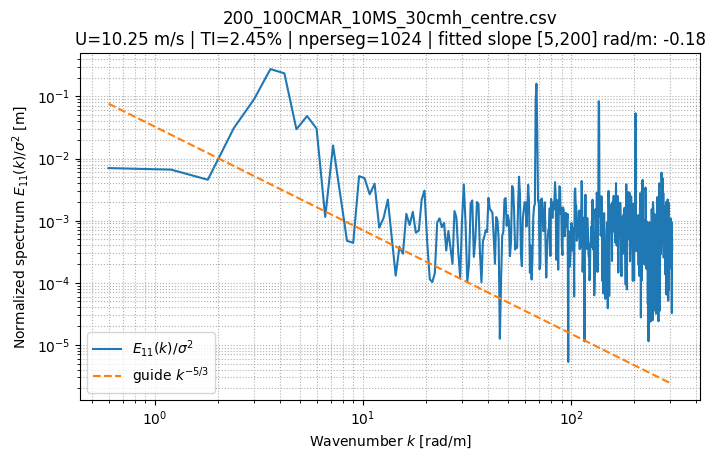

200_100CMAR_10MS_30cmh_centre.csv: U=10.255 m/s | TI=2.45% | slope=-0.18114599951919533


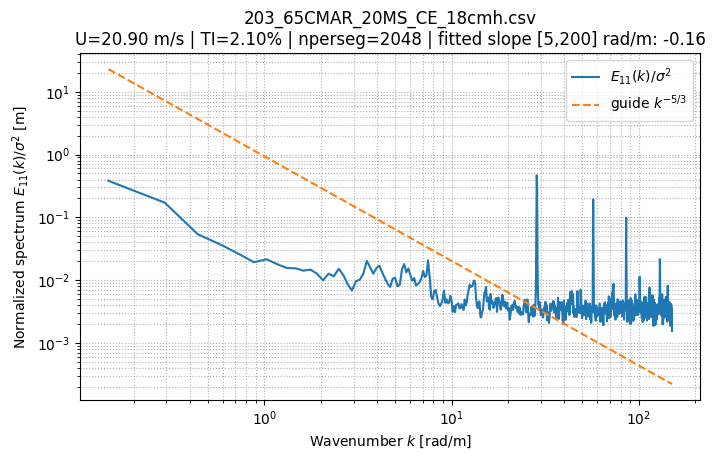

203_65CMAR_20MS_CE_18cmh.csv: U=20.900 m/s | TI=2.10% | slope=-0.15754800350443643


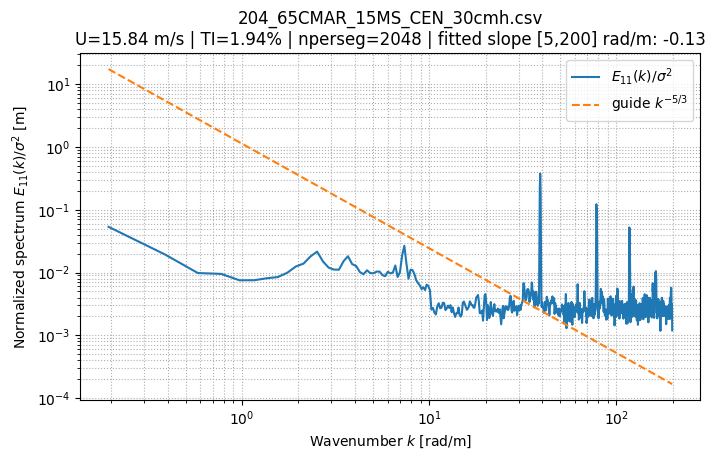

204_65CMAR_15MS_CEN_30cmh.csv: U=15.837 m/s | TI=1.94% | slope=-0.1336753400309342


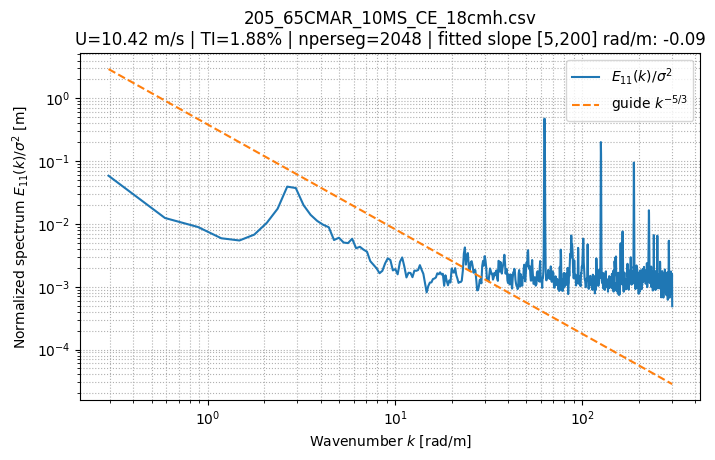

205_65CMAR_10MS_CE_18cmh.csv: U=10.423 m/s | TI=1.88% | slope=-0.09162507559967555


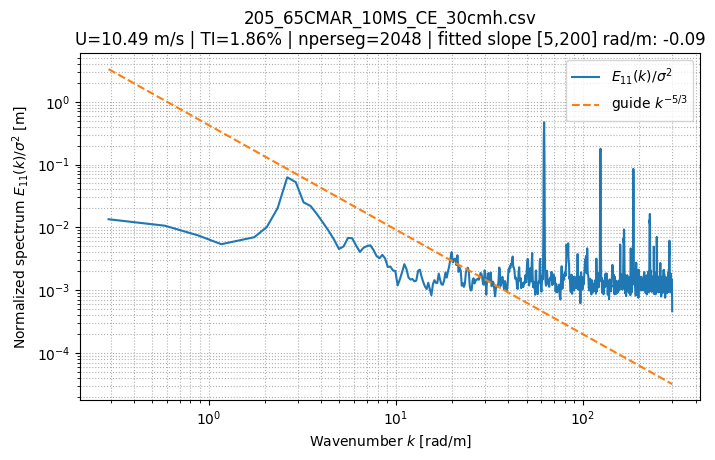

205_65CMAR_10MS_CE_30cmh.csv: U=10.490 m/s | TI=1.86% | slope=-0.0923459328257073


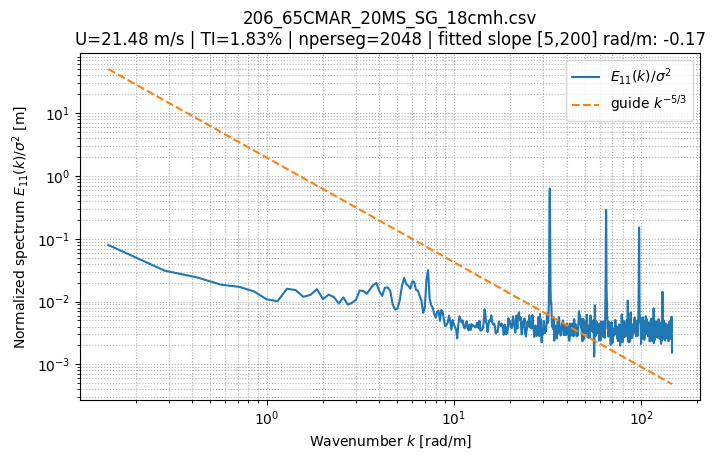

206_65CMAR_20MS_SG_18cmh.csv: U=21.477 m/s | TI=1.83% | slope=-0.17305642720825823


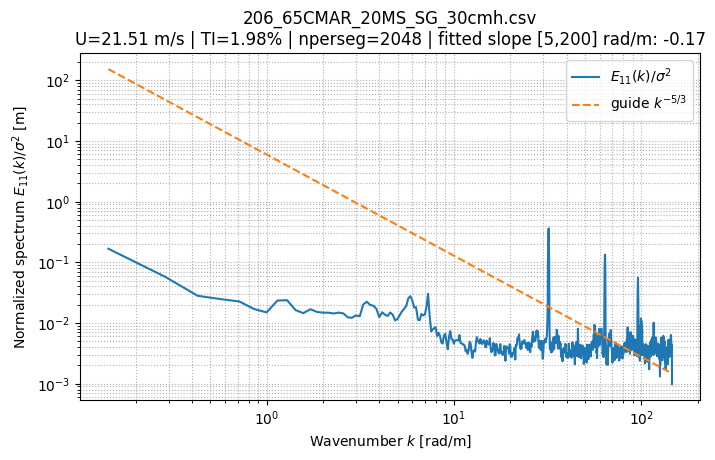

206_65CMAR_20MS_SG_30cmh.csv: U=21.510 m/s | TI=1.98% | slope=-0.1746554960142501


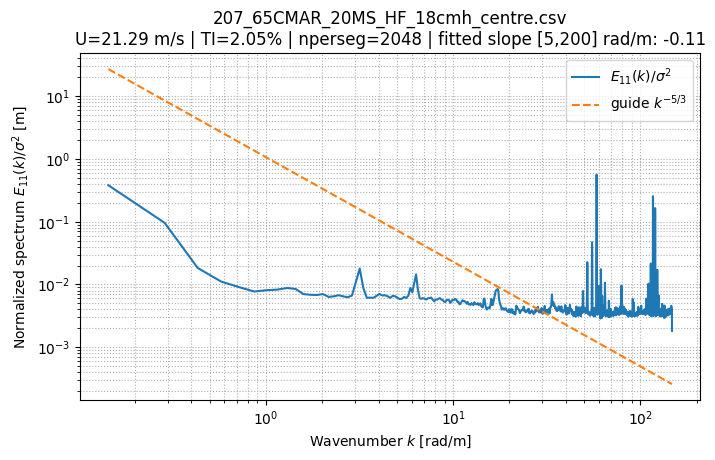

207_65CMAR_20MS_HF_18cmh_centre.csv: U=21.287 m/s | TI=2.05% | slope=-0.11094090160607877


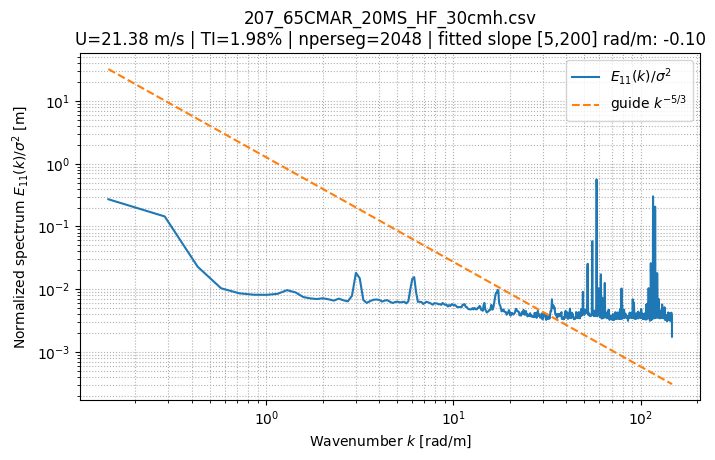

207_65CMAR_20MS_HF_30cmh.csv: U=21.384 m/s | TI=1.98% | slope=-0.10415130444630963


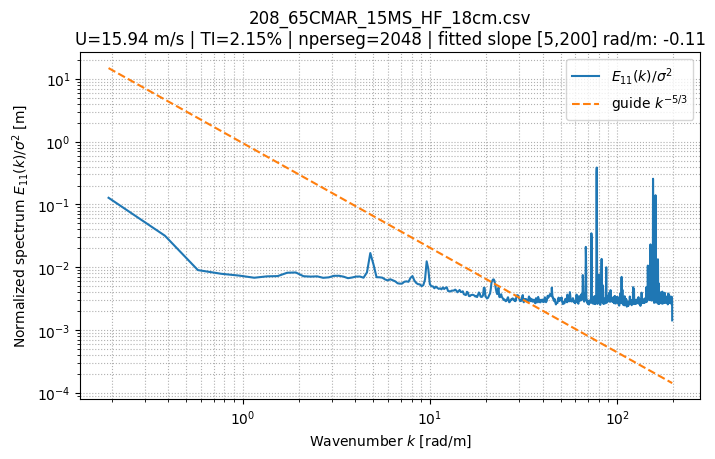

208_65CMAR_15MS_HF_18cm.csv: U=15.943 m/s | TI=2.15% | slope=-0.10904894342281998


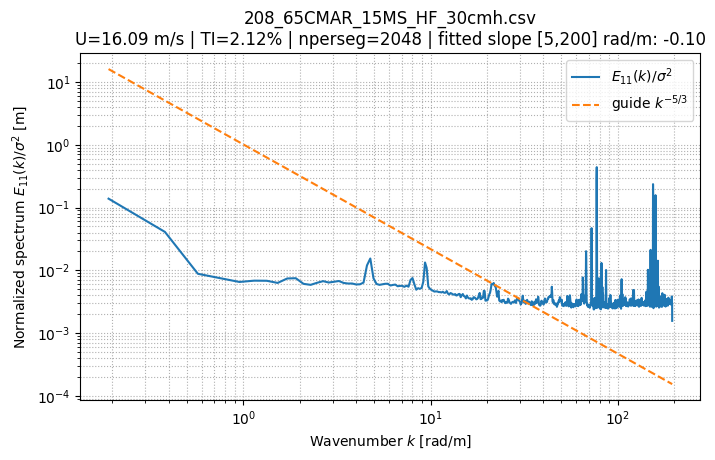

208_65CMAR_15MS_HF_30cmh.csv: U=16.086 m/s | TI=2.12% | slope=-0.10310920733940952


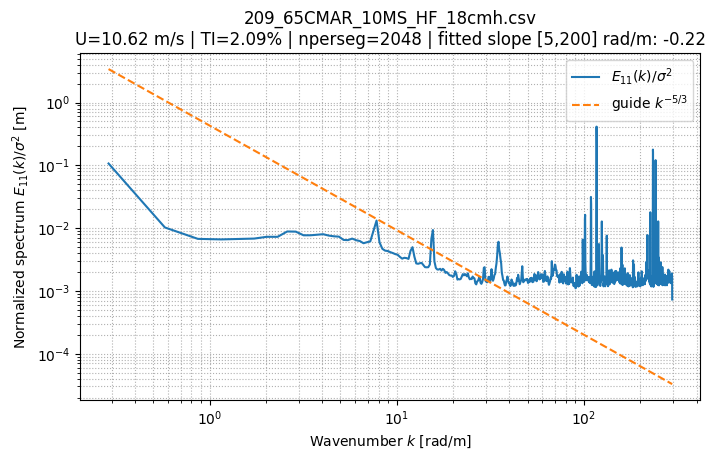

209_65CMAR_10MS_HF_18cmh.csv: U=10.620 m/s | TI=2.09% | slope=-0.22026975810028754


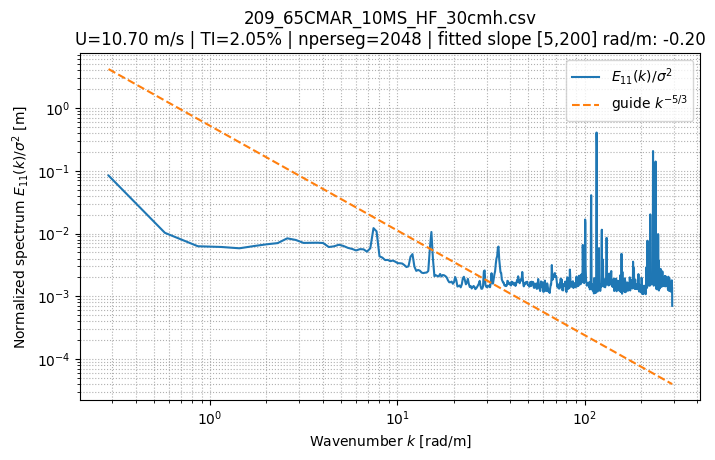

209_65CMAR_10MS_HF_30cmh.csv: U=10.699 m/s | TI=2.05% | slope=-0.197880078193646


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

# -------- SETTINGS ----------
folder_path = "/content/drive/MyDrive/THESIS IAT/TIMO CSV flute pan data/long"
fs = 1000  # Hz

nperseg_target = 2048
overlap_frac = 0.5
window = "hann"

# Pick a k-range to fit slope (you will tune after first run)
kmin_fit = 5.0     # rad/m
kmax_fit = 200.0   # rad/m
# ---------------------------

def fit_log_slope(x, y, xmin, xmax):
    m = (x >= xmin) & (x <= xmax) & np.isfinite(y) & (y > 0)
    if np.count_nonzero(m) < 10:
        return None, None, m
    slope, intercept = np.polyfit(np.log10(x[m]), np.log10(y[m]), 1)
    return slope, intercept, m

files = sorted([f for f in os.listdir(folder_path) if f.lower().endswith(".csv")])

for file in files:
    df = pd.read_csv(os.path.join(folder_path, file))

    # last column = calibrated velocity u [m/s]
    u = df.iloc[:, -1].to_numpy(dtype=float)
    u = u[np.isfinite(u)]
    if len(u) < 1000:
        print(f"Skipping {file}: too short.")
        continue

    # Mean speed and fluctuations
    U = np.mean(u)
    u_fluc = u - U
    sigma2 = np.mean(u_fluc**2)

    # Welch PSD in frequency
    nperseg = min(nperseg_target, len(u_fluc))
    if nperseg < 256:
        nperseg = len(u_fluc)
    noverlap = int(nperseg * overlap_frac)

    f, Phi_f = welch(
        u_fluc,
        fs=fs,
        window=window,
        nperseg=nperseg,
        noverlap=noverlap,
        detrend=False,
        scaling="density"
    )

    # Remove f=0 (Taylor conversion not meaningful there)
    f = f[1:]
    Phi_f = Phi_f[1:]

    # Taylor hypothesis: k = 2π f / U  (rad/m)
    k = 2 * np.pi * f / U

    # Convert PSD(f) to E11(k): E(k) = Phi(f) * U/(2π)
    E_k = Phi_f * (U / (2 * np.pi))

    # Normalize by sigma^2 if requested (gives units of length)
    E_k_norm = E_k / sigma2

    # Fit slope on chosen k-band
    slope, intercept, mfit = fit_log_slope(k, E_k_norm, kmin_fit, kmax_fit)

    # Build -5/3 guide line anchored near middle of fit band
    k_anchor = np.sqrt(kmin_fit * kmax_fit)
    idx = np.argmin(np.abs(k - k_anchor))
    guide = E_k_norm[idx] * (k / k[idx]) ** (-5/3)

    # Plot
    plt.figure(figsize=(8,4.5))
    plt.loglog(k, E_k_norm, label=r"$E_{11}(k)/\sigma^2$")
    plt.loglog(k, guide, "--", label=r"guide $k^{-5/3}$")
    plt.grid(True, which="both", ls=":")
    plt.xlabel(r"Wavenumber $k$ [rad/m]")
    plt.ylabel(r"Normalized spectrum $E_{11}(k)/\sigma^2$ [m]")
    ti_percent = 100 * np.sqrt(sigma2) / U
    title = f"{file}\nU={U:.2f} m/s | TI={ti_percent:.2f}% | nperseg={nperseg}"
    if slope is not None:
        title += f" | fitted slope [{kmin_fit:g},{kmax_fit:g}] rad/m: {slope:.2f}"
    plt.title(title)
    plt.legend()
    plt.show()

    print(f"{file}: U={U:.3f} m/s | TI={ti_percent:.2f}% | slope={slope if slope is not None else 'N/A'}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


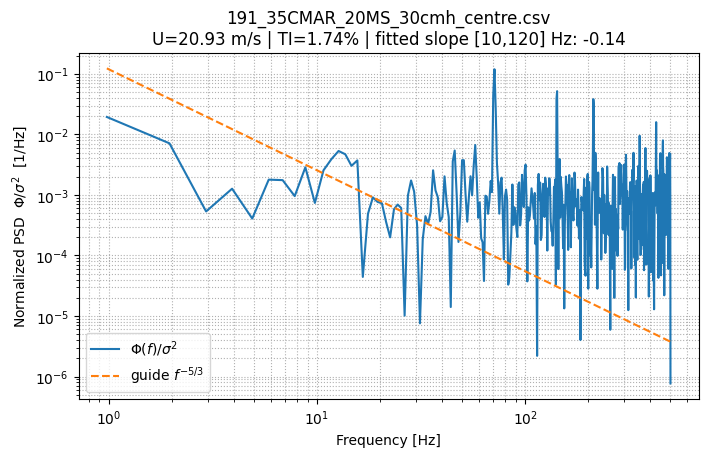

191_35CMAR_20MS_30cmh_centre.csv: TI=1.74% | slope(10.0-120.0 Hz) = -0.13636758806654173


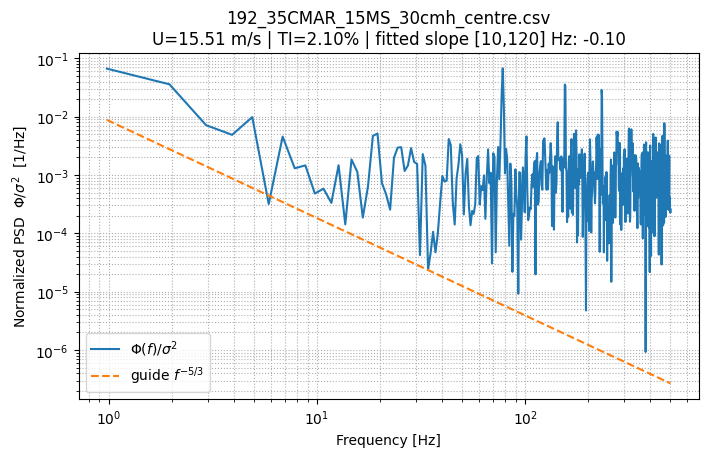

192_35CMAR_15MS_30cmh_centre.csv: TI=2.10% | slope(10.0-120.0 Hz) = -0.09624718847659226


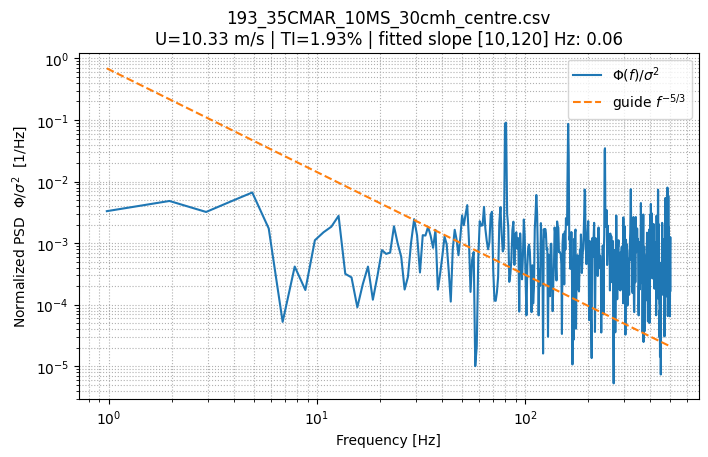

193_35CMAR_10MS_30cmh_centre.csv: TI=1.93% | slope(10.0-120.0 Hz) = 0.05684042528882901


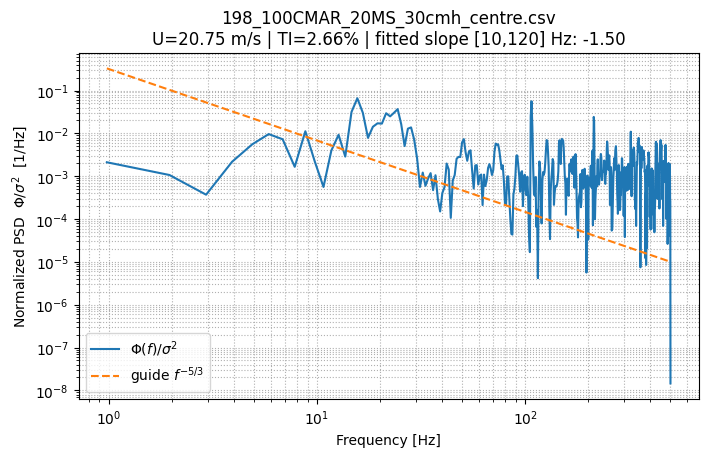

198_100CMAR_20MS_30cmh_centre.csv: TI=2.66% | slope(10.0-120.0 Hz) = -1.5024076423574837


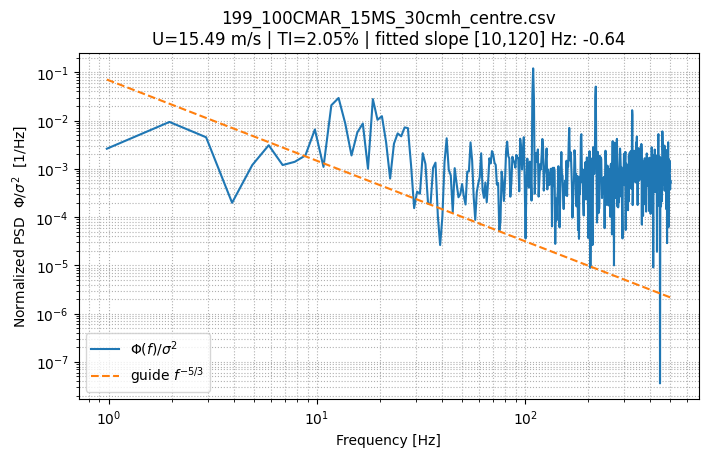

199_100CMAR_15MS_30cmh_centre.csv: TI=2.05% | slope(10.0-120.0 Hz) = -0.6389275530843612


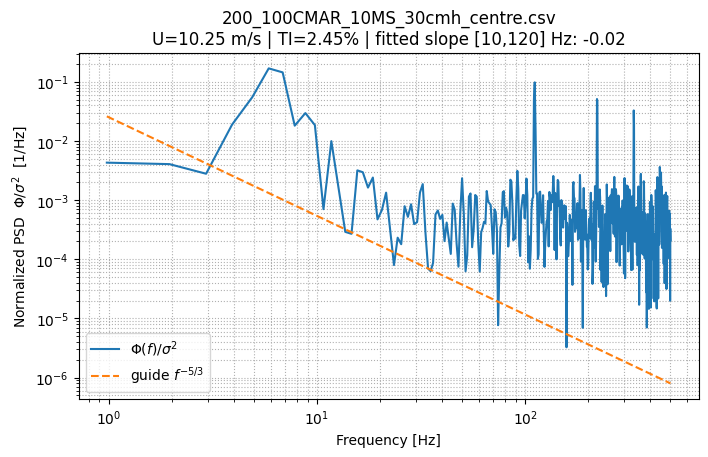

200_100CMAR_10MS_30cmh_centre.csv: TI=2.45% | slope(10.0-120.0 Hz) = -0.01941209080111339


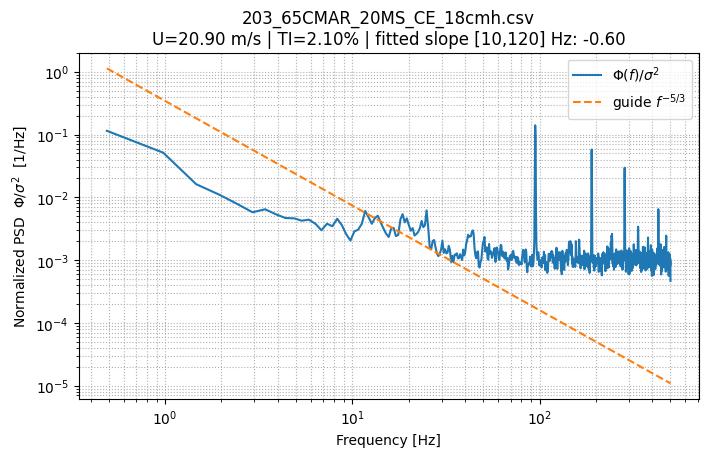

203_65CMAR_20MS_CE_18cmh.csv: TI=2.10% | slope(10.0-120.0 Hz) = -0.6039332625125512


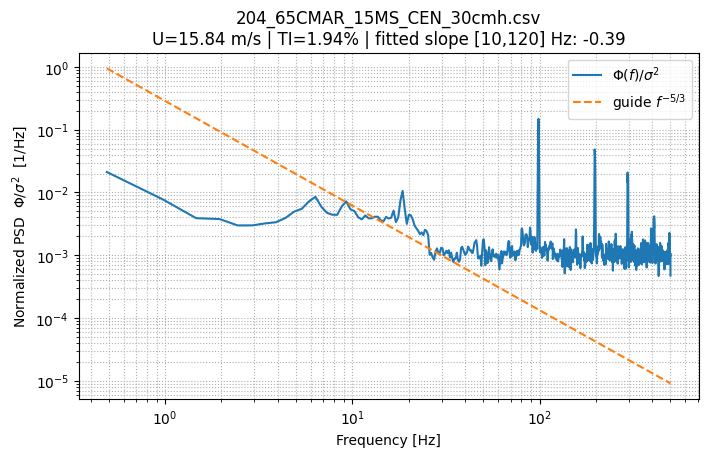

204_65CMAR_15MS_CEN_30cmh.csv: TI=1.94% | slope(10.0-120.0 Hz) = -0.3916474963490288


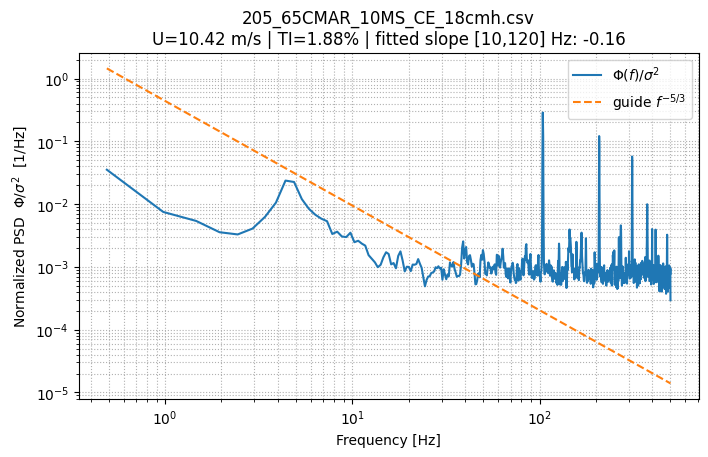

205_65CMAR_10MS_CE_18cmh.csv: TI=1.88% | slope(10.0-120.0 Hz) = -0.16408713750565962


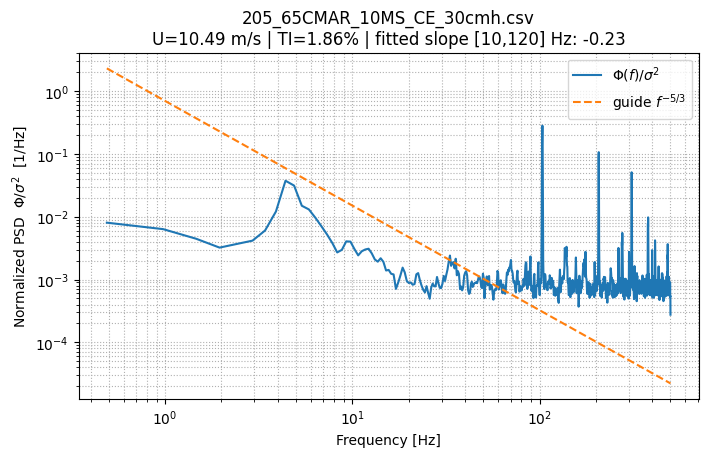

205_65CMAR_10MS_CE_30cmh.csv: TI=1.86% | slope(10.0-120.0 Hz) = -0.2329909002730334


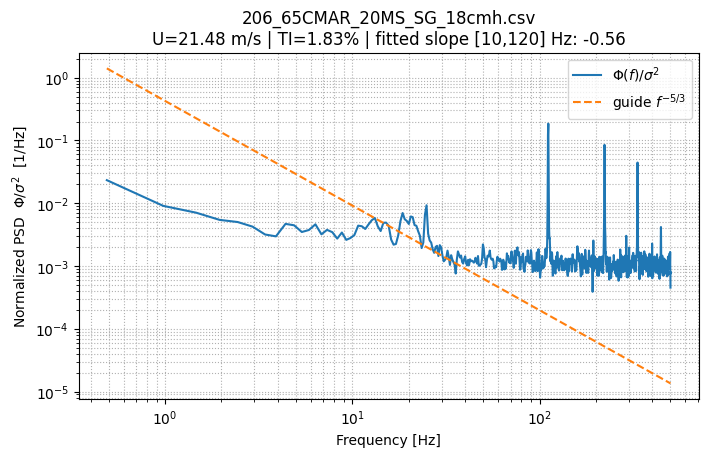

206_65CMAR_20MS_SG_18cmh.csv: TI=1.83% | slope(10.0-120.0 Hz) = -0.5576246273319408


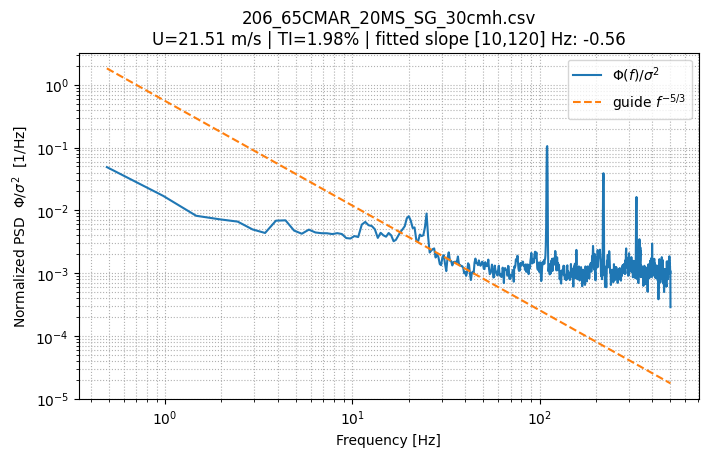

206_65CMAR_20MS_SG_30cmh.csv: TI=1.98% | slope(10.0-120.0 Hz) = -0.5617114813181944


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

# -------- SETTINGS ----------
folder_path = "/content/drive/MyDrive/THESIS IAT/TIMO CSV flute pan data/long"
fs = 1000  # Hz
nperseg_target = 2048
overlap_frac = 0.5

# Candidate inertial-range band to TEST (adjust after one run)
fmin_fit = 10.0
fmax_fit = 120.0

# Simple spike mask: ignore points where PSD is an extreme local outlier (helps with motor lines)
use_spike_mask = True
spike_threshold = 6.0  # higher = less aggressive
# ---------------------------

def fit_log_slope(freqs, y, fmin, fmax):
    m = (freqs >= fmin) & (freqs <= fmax) & np.isfinite(y) & (y > 0)
    if np.count_nonzero(m) < 10:
        return None, None, m
    xlog = np.log10(freqs[m])
    ylog = np.log10(y[m])
    slope, intercept = np.polyfit(xlog, ylog, 1)
    return slope, intercept, m

files = sorted([f for f in os.listdir(folder_path) if f.lower().endswith(".csv")])

for file in files:
    df = pd.read_csv(os.path.join(folder_path, file))

    u = df.iloc[:, -1].to_numpy(dtype=float)
    u = u[np.isfinite(u)]
    if len(u) < 1000:
        print(f"Skipping {file}: too short.")
        continue

    U = np.mean(u)
    u_fluc = u - U
    sigma2 = np.mean(u_fluc**2)

    freqs, psd = welch(
        u_fluc,
        fs=fs,
        window="hann",
        nperseg=min(nperseg_target, len(u_fluc)),
        noverlap=int(min(nperseg_target, len(u_fluc)) * overlap_frac),
        detrend=False,
        scaling="density"
    )

    # Normalize: PSD / sigma^2  (units 1/Hz)
    psd_norm = psd / sigma2

    # drop f=0
    freqs = freqs[1:]
    psd_norm = psd_norm[1:]

    # Optional: mask sharp narrow spikes (motor lines) using a robust log-space deviation test
    mask = np.ones_like(psd_norm, dtype=bool)
    if use_spike_mask:
        ylog = np.log(psd_norm)
        # rolling median using a simple window
        w = 9
        med = np.array([np.median(ylog[max(0,i-w):min(len(ylog),i+w+1)]) for i in range(len(ylog))])
        dev = np.abs(ylog - med)
        mad = np.median(dev) + 1e-12
        mask &= (dev < spike_threshold * mad)

    # Fit slope on the candidate band
    slope, intercept, fitmask = fit_log_slope(freqs[mask], psd_norm[mask], fmin_fit, fmax_fit)

    # Build -5/3 guide line anchored at f_anchor in the middle of fit range
    f_anchor = np.sqrt(fmin_fit * fmax_fit)
    idx = np.argmin(np.abs(freqs - f_anchor))
    guide = psd_norm[idx] * (freqs / freqs[idx]) ** (-5/3)

    # Plot
    plt.figure(figsize=(8,4.5))
    plt.loglog(freqs, psd_norm, label=r"$\Phi(f)/\sigma^2$")
    plt.loglog(freqs, guide, "--", label=r"guide $f^{-5/3}$")
    plt.grid(True, which="both", ls=":")
    plt.xlabel("Frequency [Hz]")
    plt.ylabel(r"Normalized PSD  $\Phi/\sigma^2$  [1/Hz]")

    ti_percent = 100 * np.sqrt(sigma2) / U
    title = f"{file}\nU={U:.2f} m/s | TI={ti_percent:.2f}%"
    if slope is not None:
        title += f" | fitted slope [{fmin_fit:g},{fmax_fit:g}] Hz: {slope:.2f}"
    else:
        title += f" | not enough points to fit slope"
    plt.title(title)
    plt.legend()
    plt.show()

    print(f"{file}: TI={ti_percent:.2f}% | slope({fmin_fit}-{fmax_fit} Hz) = {slope if slope is not None else 'N/A'}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/tmp/ipython-input-3304307169.py:74: RuntimeWarning: divide by zero encountered in power
  guide = y0 * (freqs / f0) ** (-5/3)


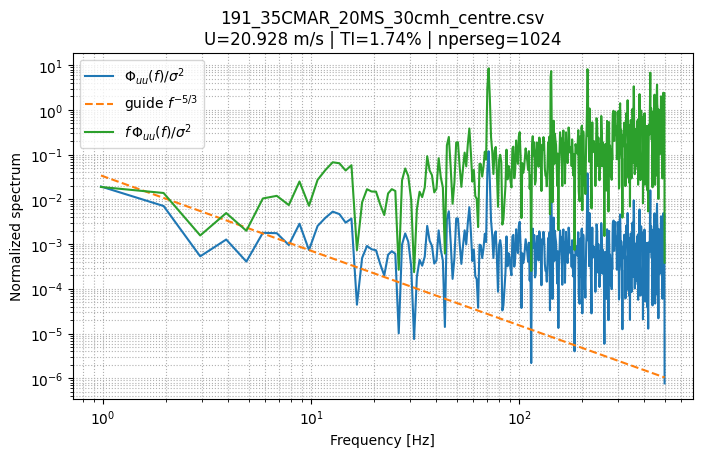

/tmp/ipython-input-3304307169.py:74: RuntimeWarning: divide by zero encountered in power
  guide = y0 * (freqs / f0) ** (-5/3)


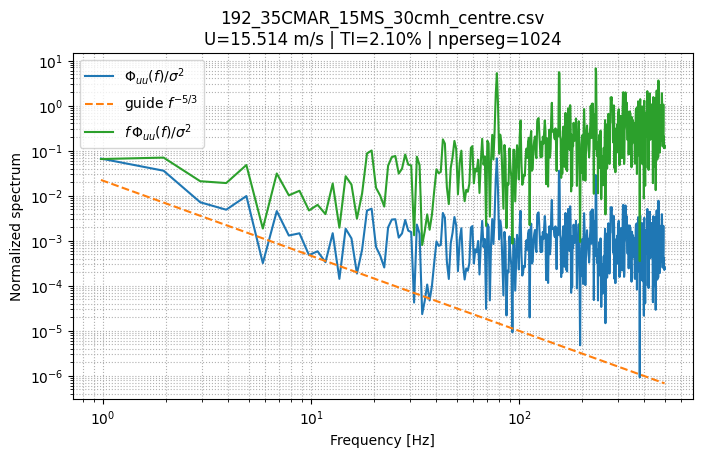

/tmp/ipython-input-3304307169.py:74: RuntimeWarning: divide by zero encountered in power
  guide = y0 * (freqs / f0) ** (-5/3)


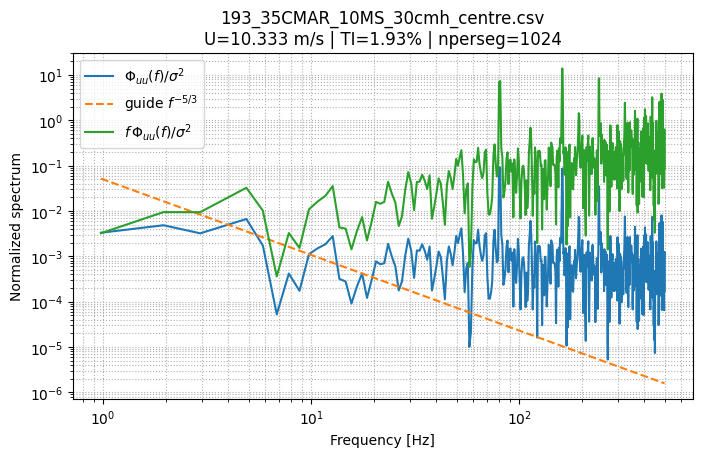

/tmp/ipython-input-3304307169.py:74: RuntimeWarning: divide by zero encountered in power
  guide = y0 * (freqs / f0) ** (-5/3)


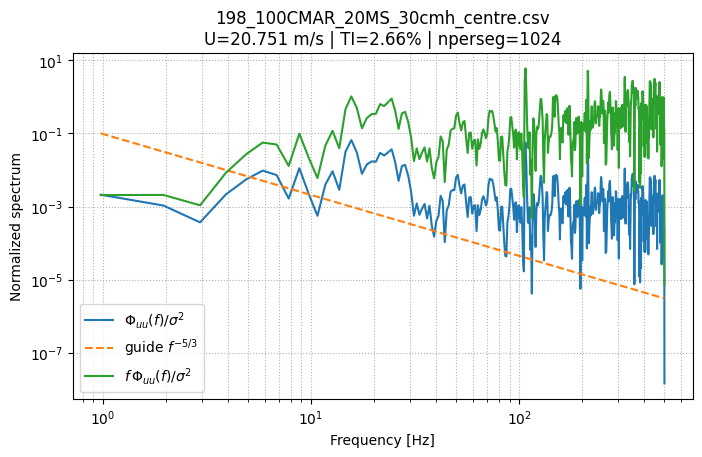

/tmp/ipython-input-3304307169.py:74: RuntimeWarning: divide by zero encountered in power
  guide = y0 * (freqs / f0) ** (-5/3)


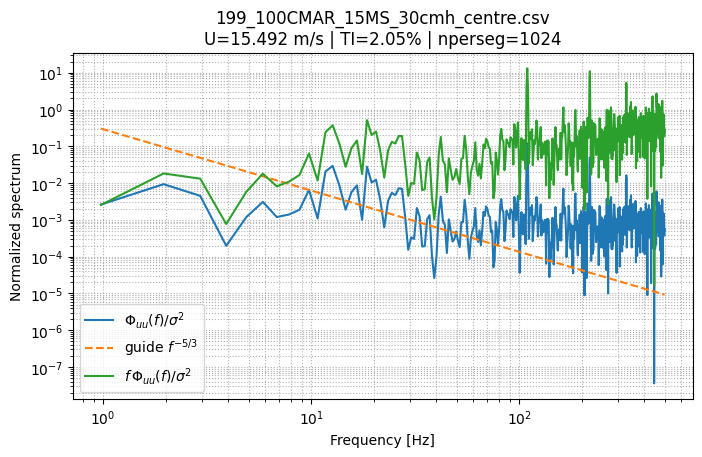

/tmp/ipython-input-3304307169.py:74: RuntimeWarning: divide by zero encountered in power
  guide = y0 * (freqs / f0) ** (-5/3)


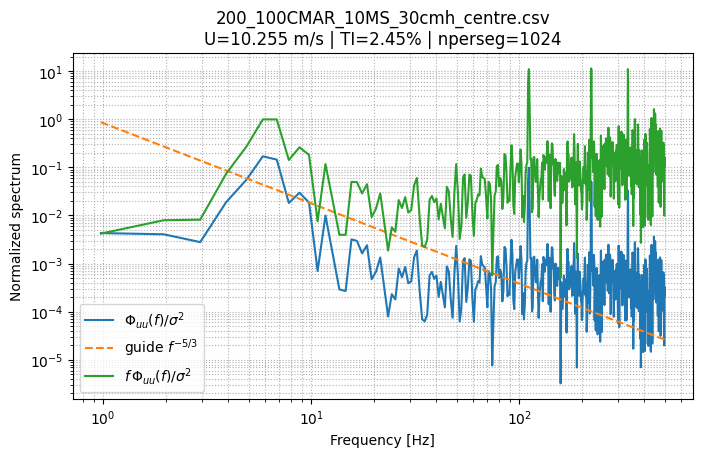

/tmp/ipython-input-3304307169.py:74: RuntimeWarning: divide by zero encountered in power
  guide = y0 * (freqs / f0) ** (-5/3)


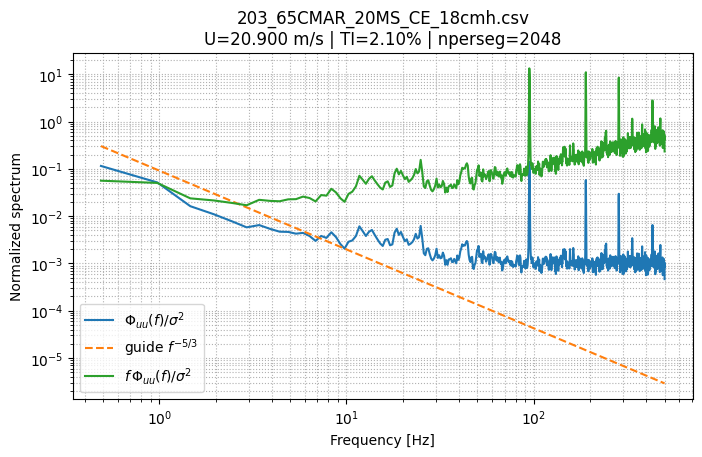

/tmp/ipython-input-3304307169.py:74: RuntimeWarning: divide by zero encountered in power
  guide = y0 * (freqs / f0) ** (-5/3)


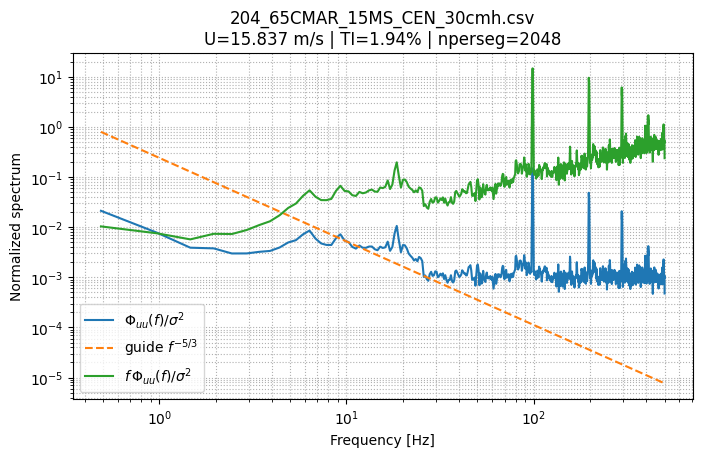

/tmp/ipython-input-3304307169.py:74: RuntimeWarning: divide by zero encountered in power
  guide = y0 * (freqs / f0) ** (-5/3)


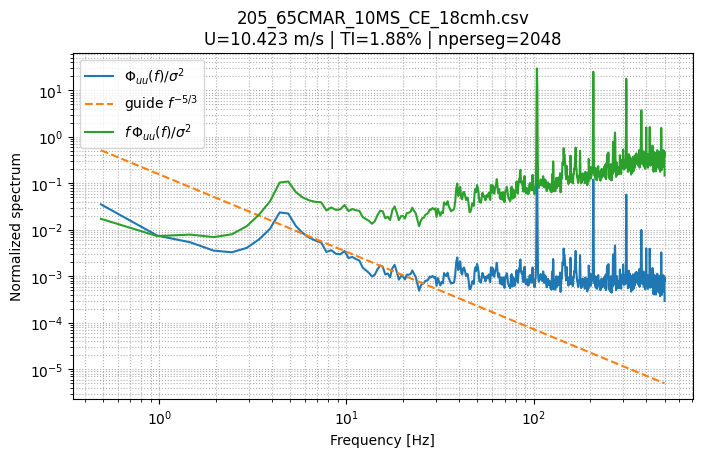

/tmp/ipython-input-3304307169.py:74: RuntimeWarning: divide by zero encountered in power
  guide = y0 * (freqs / f0) ** (-5/3)


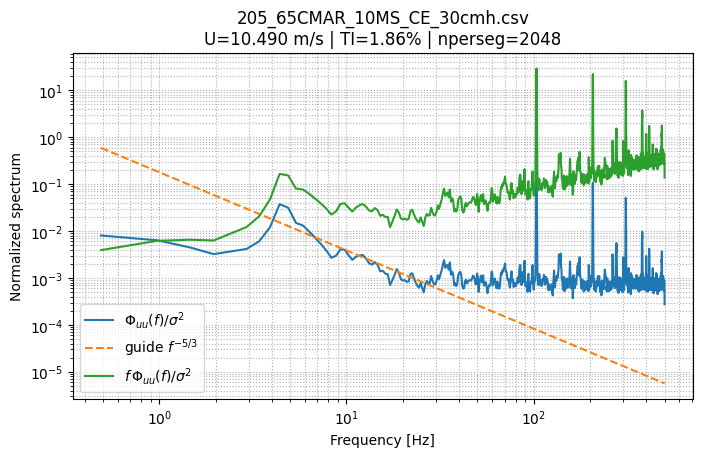

/tmp/ipython-input-3304307169.py:74: RuntimeWarning: divide by zero encountered in power
  guide = y0 * (freqs / f0) ** (-5/3)


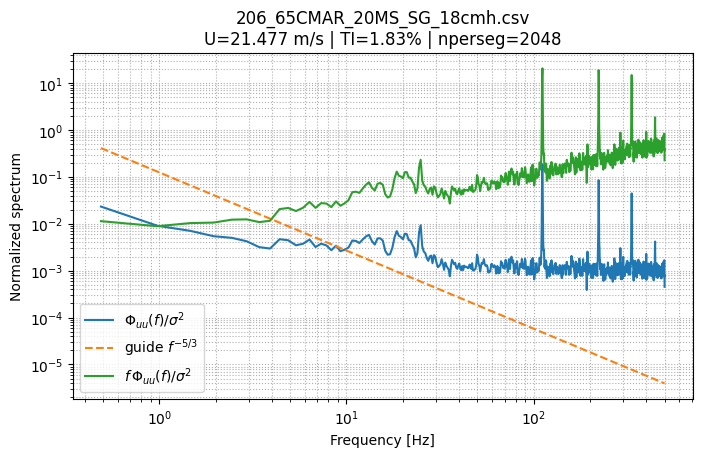

/tmp/ipython-input-3304307169.py:74: RuntimeWarning: divide by zero encountered in power
  guide = y0 * (freqs / f0) ** (-5/3)


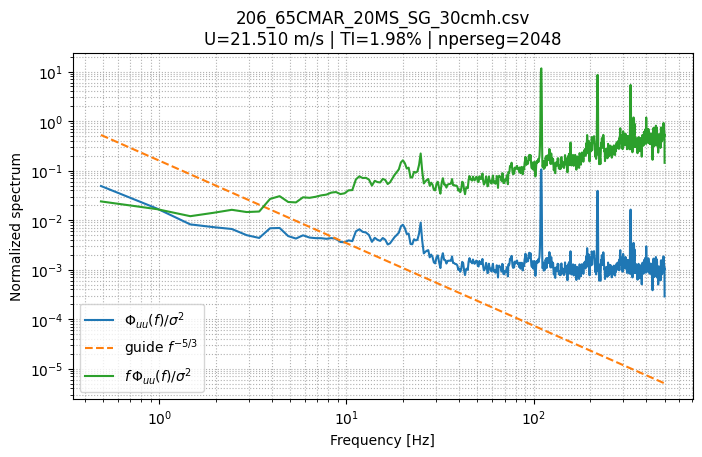

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

# -------- SETTINGS ----------
folder_path = "/content/drive/MyDrive/THESIS IAT/TIMO CSV flute pan data/long"
fs = 1000  # Hz

nperseg_target = 2048
window = "hann"
overlap_frac = 0.5

# choose what to plot:
plot_f_psd_over_var = True   # plots f*PSD/sigma^2 (dimensionless)
plot_psd_over_var = True     # plots PSD/sigma^2 (1/Hz)

# choose a frequency band to anchor the -5/3 guide line (adjust if needed)
f_anchor = 10.0  # Hz (pick inside the region you think is inertial)
# ----------------------------

files = sorted([f for f in os.listdir(folder_path) if f.lower().endswith(".csv")])

for file in files:
    df = pd.read_csv(os.path.join(folder_path, file))

    # last column: calibrated velocity u [m/s] (or your signal)
    u = df.iloc[:, -1].to_numpy(dtype=float)
    u = u[np.isfinite(u)]
    n = len(u)
    if n < 10:
        print(f"Skipping {file}: not enough samples.")
        continue

    # mean and fluctuations
    U = np.mean(u)
    u_fluc = u - U

    # sigma^2 = variance of fluctuations
    sigma2 = np.mean(u_fluc**2)  # ddof=0
    if sigma2 <= 0:
        print(f"Skipping {file}: sigma^2 <= 0.")
        continue

    # Welch PSD of u'
    nperseg = min(nperseg_target, n)
    if nperseg < 256:
        nperseg = n
    noverlap = int(nperseg * overlap_frac)

    freqs, psd = welch(
        u_fluc,
        fs=fs,
        window=window,
        nperseg=nperseg,
        noverlap=noverlap,
        detrend=False,
        scaling="density"
    )

    # normalized spectra
    psd_norm = psd / sigma2            # units: 1/Hz
    f_psd_norm = freqs * psd_norm      # dimensionless

    # Build a -5/3 guide line for PSD/sigma^2
    # We scale it to match the curve at f_anchor (nearest point)
    idx = np.argmin(np.abs(freqs - f_anchor))
    f0 = freqs[idx]
    y0 = psd_norm[idx]
    guide = y0 * (freqs / f0) ** (-5/3)

    # Plot
    plt.figure(figsize=(8, 4.5))

    if plot_psd_over_var:
        plt.loglog(freqs[1:], psd_norm[1:], label=r"$\Phi_{uu}(f)/\sigma^2$")
        plt.loglog(freqs[1:], guide[1:], "--", label=r"guide $f^{-5/3}$")

    if plot_f_psd_over_var:
        plt.loglog(freqs[1:], f_psd_norm[1:], label=r"$f\,\Phi_{uu}(f)/\sigma^2$")

    plt.grid(True, which="both", ls=":")
    plt.xlabel("Frequency [Hz]")
    plt.ylabel("Normalized spectrum")
    plt.title(f"{file}\nU={U:.3f} m/s | TI={100*np.sqrt(sigma2)/U:.2f}% | nperseg={nperseg}")
    plt.legend()
    plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


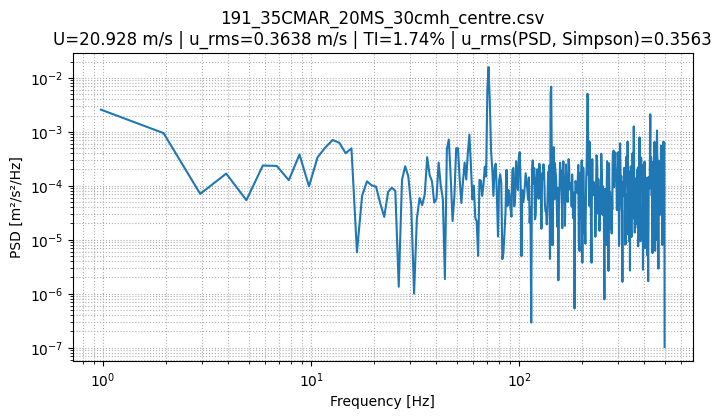

File: 191_35CMAR_20MS_30cmh_centre.csv
  Samples: 1024
  Mean speed U = 20.928058 m/s
  u_rms (time domain) = 0.363795 m/s
  Turbulence intensity TI = 1.738 %
  u_rms (PSD, Simpson) = 0.356325 m/s (cross-check)
  Relative diff (PSD vs time) = -2.053 %
------------------------------------------------------------


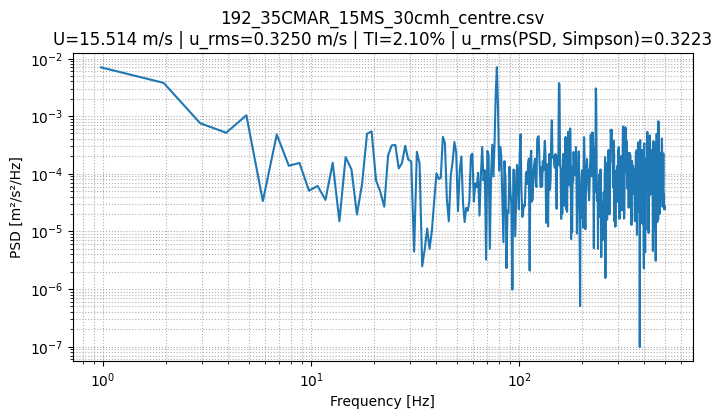

File: 192_35CMAR_15MS_30cmh_centre.csv
  Samples: 1024
  Mean speed U = 15.513969 m/s
  u_rms (time domain) = 0.325048 m/s
  Turbulence intensity TI = 2.095 %
  u_rms (PSD, Simpson) = 0.322299 m/s (cross-check)
  Relative diff (PSD vs time) = -0.846 %
------------------------------------------------------------


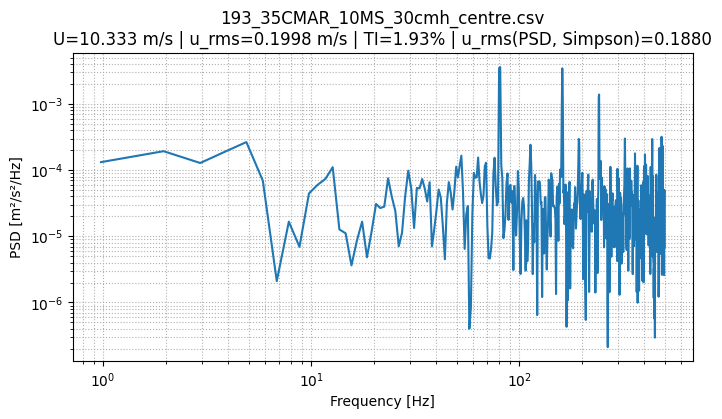

File: 193_35CMAR_10MS_30cmh_centre.csv
  Samples: 1024
  Mean speed U = 10.333174 m/s
  u_rms (time domain) = 0.199763 m/s
  Turbulence intensity TI = 1.933 %
  u_rms (PSD, Simpson) = 0.187977 m/s (cross-check)
  Relative diff (PSD vs time) = -5.900 %
------------------------------------------------------------


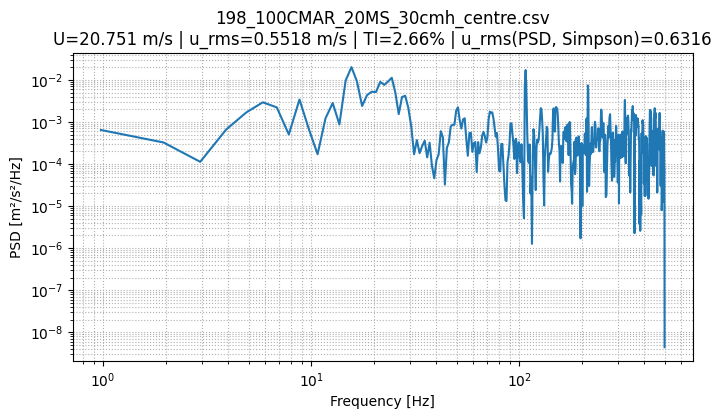

File: 198_100CMAR_20MS_30cmh_centre.csv
  Samples: 1024
  Mean speed U = 20.750797 m/s
  u_rms (time domain) = 0.551776 m/s
  Turbulence intensity TI = 2.659 %
  u_rms (PSD, Simpson) = 0.631579 m/s (cross-check)
  Relative diff (PSD vs time) = 14.463 %
------------------------------------------------------------


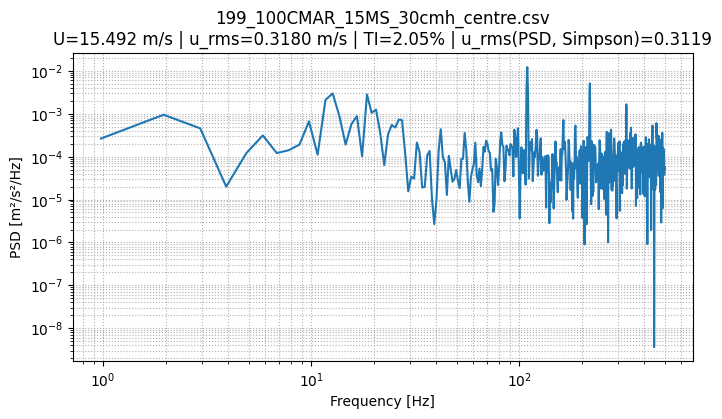

File: 199_100CMAR_15MS_30cmh_centre.csv
  Samples: 1024
  Mean speed U = 15.492042 m/s
  u_rms (time domain) = 0.318027 m/s
  Turbulence intensity TI = 2.053 %
  u_rms (PSD, Simpson) = 0.311865 m/s (cross-check)
  Relative diff (PSD vs time) = -1.938 %
------------------------------------------------------------


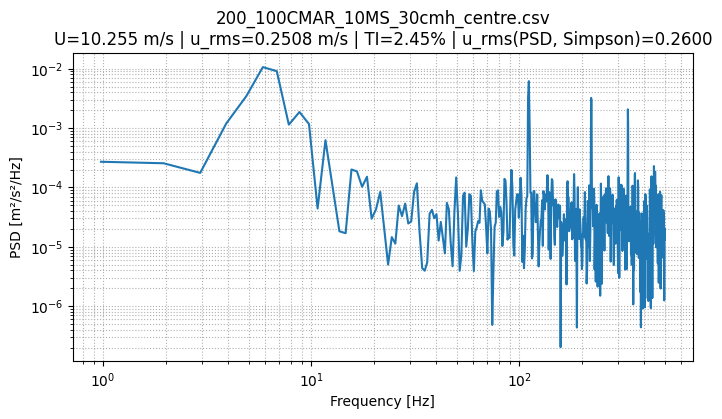

File: 200_100CMAR_10MS_30cmh_centre.csv
  Samples: 1024
  Mean speed U = 10.254707 m/s
  u_rms (time domain) = 0.250814 m/s
  Turbulence intensity TI = 2.446 %
  u_rms (PSD, Simpson) = 0.259956 m/s (cross-check)
  Relative diff (PSD vs time) = 3.645 %
------------------------------------------------------------


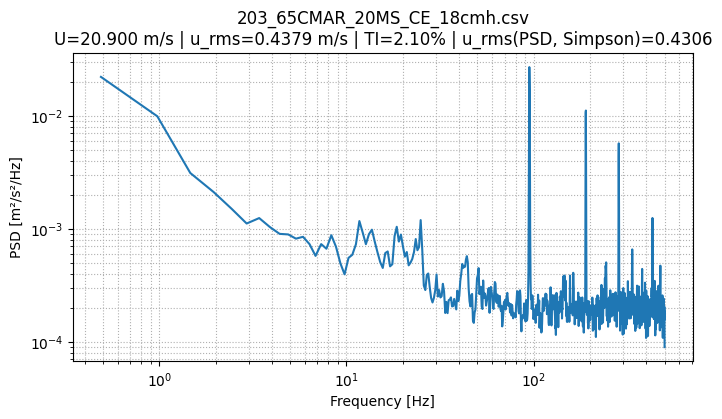

File: 203_65CMAR_20MS_CE_18cmh.csv
  Samples: 30000
  Mean speed U = 20.900013 m/s
  u_rms (time domain) = 0.437867 m/s
  Turbulence intensity TI = 2.095 %
  u_rms (PSD, Simpson) = 0.430634 m/s (cross-check)
  Relative diff (PSD vs time) = -1.652 %
------------------------------------------------------------


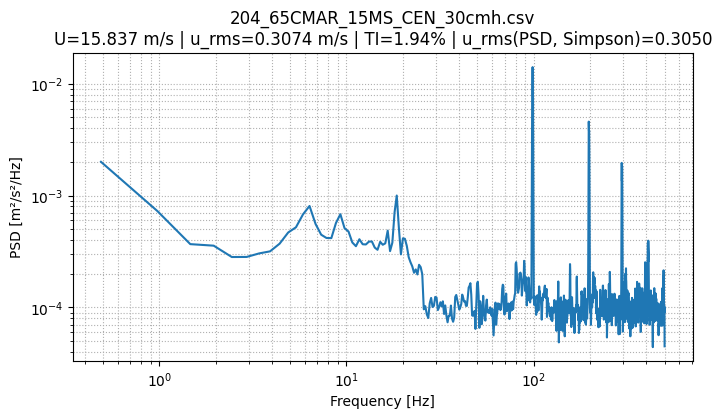

File: 204_65CMAR_15MS_CEN_30cmh.csv
  Samples: 30000
  Mean speed U = 15.837150 m/s
  u_rms (time domain) = 0.307401 m/s
  Turbulence intensity TI = 1.941 %
  u_rms (PSD, Simpson) = 0.305029 m/s (cross-check)
  Relative diff (PSD vs time) = -0.772 %
------------------------------------------------------------


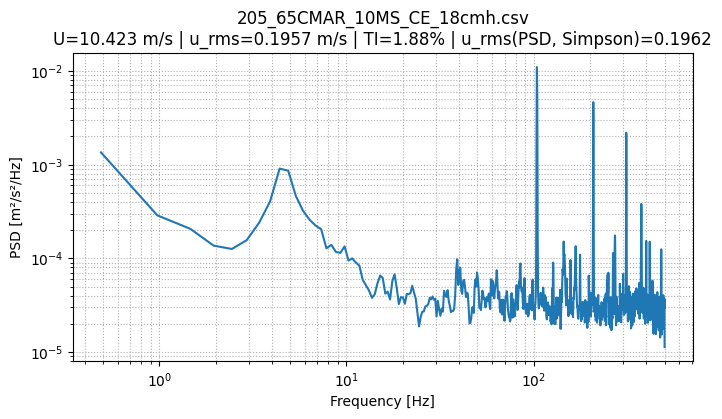

File: 205_65CMAR_10MS_CE_18cmh.csv
  Samples: 30000
  Mean speed U = 10.422625 m/s
  u_rms (time domain) = 0.195694 m/s
  Turbulence intensity TI = 1.878 %
  u_rms (PSD, Simpson) = 0.196198 m/s (cross-check)
  Relative diff (PSD vs time) = 0.257 %
------------------------------------------------------------


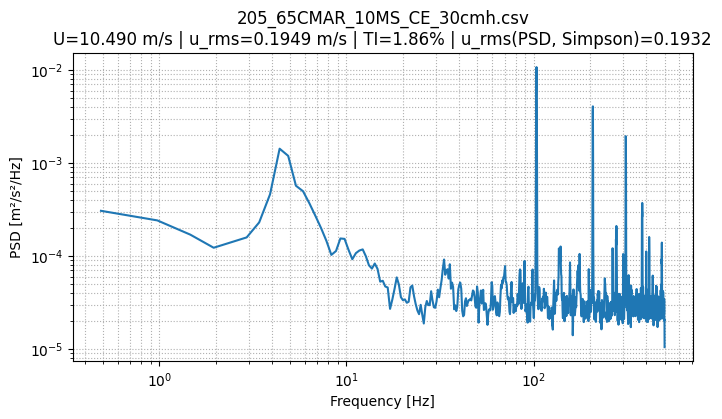

File: 205_65CMAR_10MS_CE_30cmh.csv
  Samples: 30000
  Mean speed U = 10.490393 m/s
  u_rms (time domain) = 0.194918 m/s
  Turbulence intensity TI = 1.858 %
  u_rms (PSD, Simpson) = 0.193219 m/s (cross-check)
  Relative diff (PSD vs time) = -0.871 %
------------------------------------------------------------


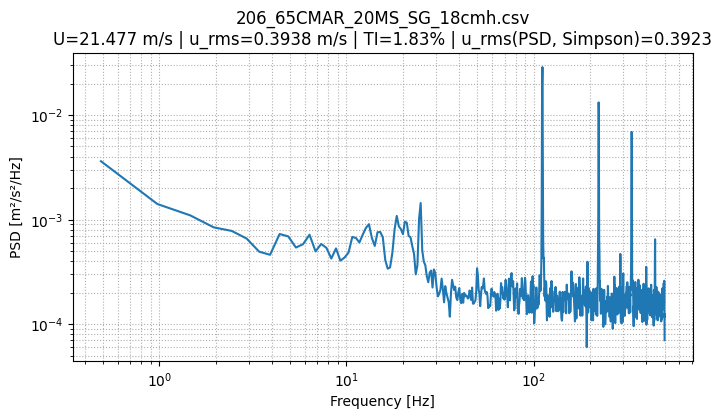

File: 206_65CMAR_20MS_SG_18cmh.csv
  Samples: 30000
  Mean speed U = 21.476803 m/s
  u_rms (time domain) = 0.393817 m/s
  Turbulence intensity TI = 1.834 %
  u_rms (PSD, Simpson) = 0.392345 m/s (cross-check)
  Relative diff (PSD vs time) = -0.374 %
------------------------------------------------------------


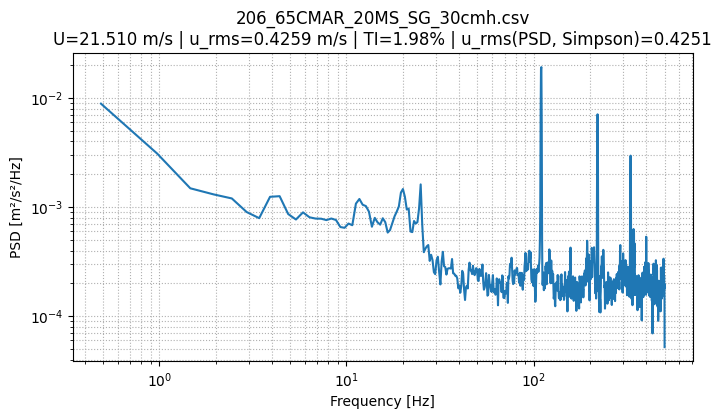

File: 206_65CMAR_20MS_SG_30cmh.csv
  Samples: 30000
  Mean speed U = 21.510080 m/s
  u_rms (time domain) = 0.425862 m/s
  Turbulence intensity TI = 1.980 %
  u_rms (PSD, Simpson) = 0.425122 m/s (cross-check)
  Relative diff (PSD vs time) = -0.174 %
------------------------------------------------------------


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch
from scipy.integrate import simpson

# -------- SETTINGS ----------
folder_path = "/content/drive/MyDrive/THESIS IAT/TIMO CSV flute pan data/long"
fs = 1000  # Hz

# Welch settings (keep constant across cases for fair comparison)
nperseg_target = 2048
window = "hann"
overlap_frac = 0.5
# ----------------------------

files = sorted([f for f in os.listdir(folder_path) if f.lower().endswith(".csv")])

for file in files:
    df = pd.read_csv(os.path.join(folder_path, file))

    # Assume last column is calibrated velocity in m/s
    u = df.iloc[:, -1].to_numpy(dtype=float)
    u = u[np.isfinite(u)]
    n = len(u)
    if n < 10:
        print(f"Skipping {file}: not enough samples.")
        continue

    # ---- Mean and fluctuations ----
    U = np.mean(u)
    u_fluc = u - U

    # ---- MOST PRECISE: time-domain RMS ----
    u_rms = np.sqrt(np.mean(u_fluc**2))   # same as np.std(u_fluc, ddof=0)

    TI = u_rms / U
    TI_percent = 100 * TI

    # ---- Welch PSD (for spectral shape + optional variance check) ----
    nperseg = min(nperseg_target, n)
    if nperseg < 256:
        nperseg = n
    noverlap = int(nperseg * overlap_frac)

    freqs, psd = welch(
        u_fluc,
        fs=fs,
        window=window,
        nperseg=nperseg,
        noverlap=noverlap,
        detrend=False,
        scaling="density"
    )

    # ---- Optional cross-check: Simpson integration of PSD ----
    # For a one-sided PSD from welch, integral(PSD df) ≈ variance.
    var_psd_simpson = simpson(psd, freqs)
    u_rms_psd = np.sqrt(var_psd_simpson)

    # ---- Plot ----
    plt.figure(figsize=(8,4))
    plt.loglog(freqs[1:], psd[1:])  # skip f=0 for log scale
    plt.grid(True, which="both", ls=":")
    plt.xlabel("Frequency [Hz]")
    plt.ylabel("PSD [m²/s²/Hz]")
    plt.title(
        f"{file}\n"
        f"U={U:.3f} m/s | u_rms={u_rms:.4f} m/s | TI={TI_percent:.2f}% | "
        f"u_rms(PSD, Simpson)={u_rms_psd:.4f}"
    )
    plt.show()

    # ---- Print summary ----
    print(f"File: {file}")
    print(f"  Samples: {n}")
    print(f"  Mean speed U = {U:.6f} m/s")
    print(f"  u_rms (time domain) = {u_rms:.6f} m/s")
    print(f"  Turbulence intensity TI = {TI_percent:.3f} %")
    print(f"  u_rms (PSD, Simpson) = {u_rms_psd:.6f} m/s (cross-check)")
    print(f"  Relative diff (PSD vs time) = {(u_rms_psd - u_rms)/u_rms * 100:.3f} %")
    print("-" * 60)

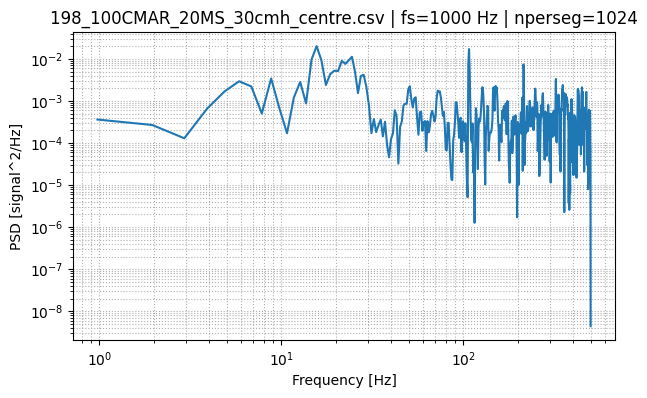

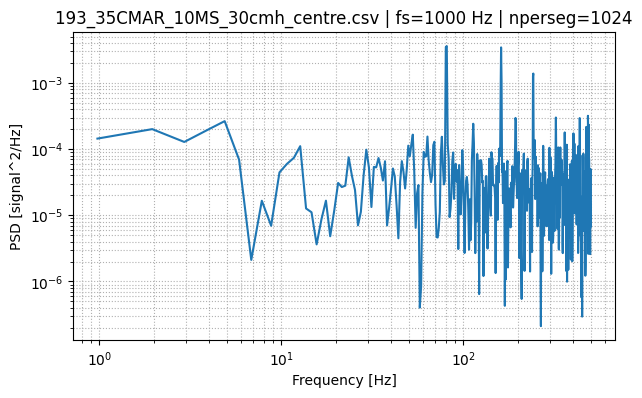

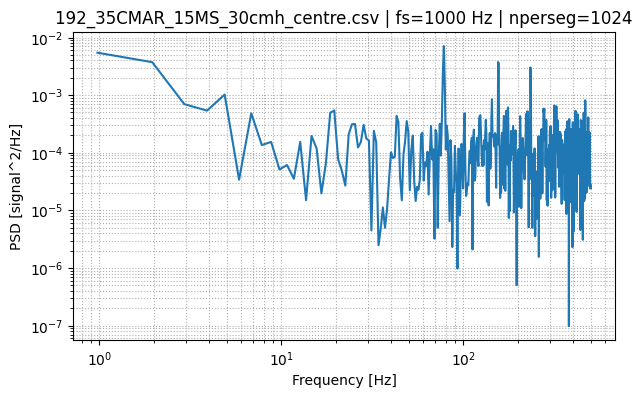

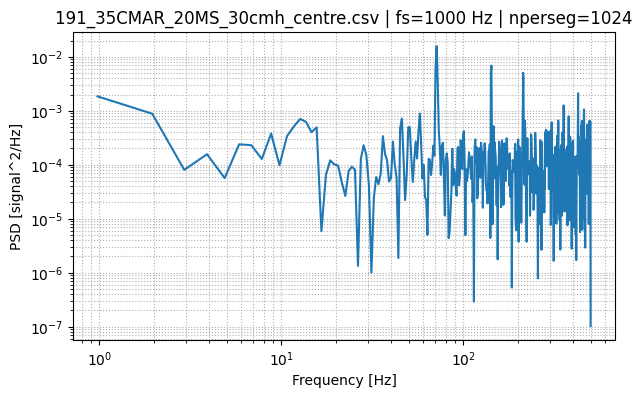

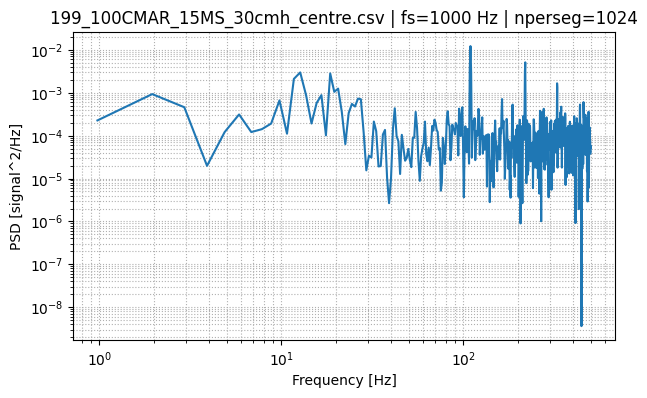

...

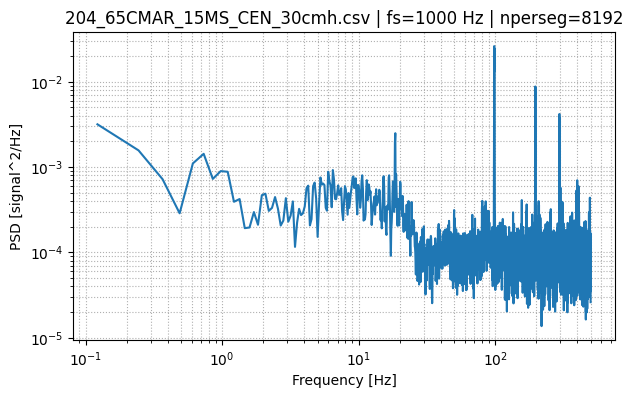

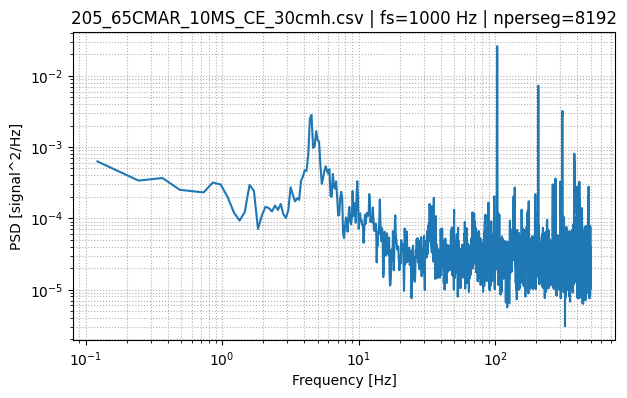

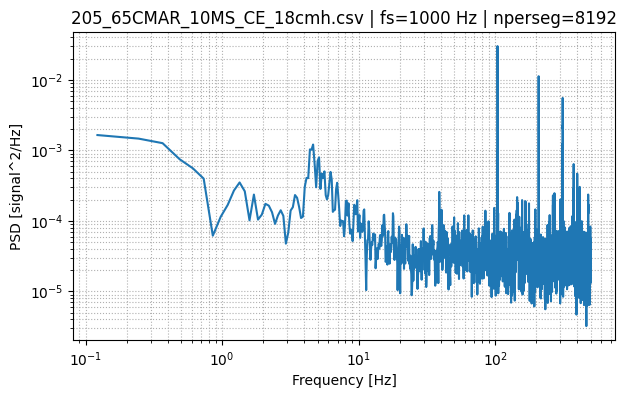

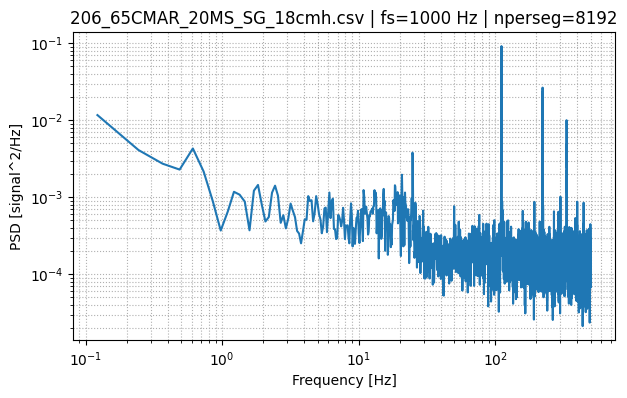

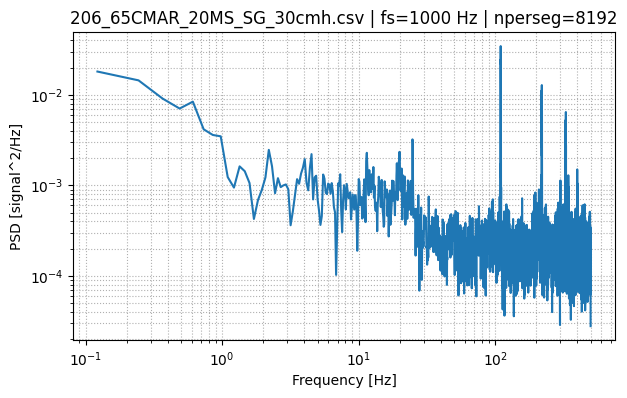

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch, detrend

folder_path = "/content/drive/MyDrive/THESIS IAT/TIMO CSV flute pan data/long"
files = [f for f in os.listdir(folder_path) if f.endswith(".csv")]

fs = 1000  # Hz (your sampling rate)

for file in files:
    df = pd.read_csv(os.path.join(folder_path, file))

    # last column = signal
    x = df.iloc[:, -1].to_numpy(dtype=float)
    x = x[np.isfinite(x)]

    # remove drift + mean
    x = detrend(x, type="linear")

    # Welch settings: tune nperseg to balance low-f resolution vs variance
    n = len(x)
    nperseg = min(8192, n)           # try 4096 / 8192 / 16384 if you have long records
    if nperseg < 256:
        nperseg = n

    freqs, psd = welch(
        x,
        fs=fs,
        window="hann",
        nperseg=nperseg,
        noverlap=nperseg // 2,
        detrend=False,
        scaling="density"
    )

    plt.figure(figsize=(7,4))
    plt.loglog(freqs[1:], psd[1:])   # skip f=0 for log scale
    plt.title(f"{file} | fs={fs} Hz | nperseg={nperseg}")
    plt.xlabel("Frequency [Hz]")
    plt.ylabel("PSD [signal^2/Hz]")
    plt.grid(True, which="both", ls=":")
    plt.show()